# Does historical-error uncertainty improve frozen capacity planning?
**Question:** with point forecasts, physical constraints, costs and the frozen
decision protocol held fixed, does accounting for forecast-error dispersion reduce
modeled cost? The principal comparison is **C versus B**, not forecasting accuracy.

| Policy | Forecast inputs | Optimizer |
| --- | --- | --- |
| A: Persistence | Latest observed available/occupied values repeated for three months | Deterministic |
| B: ML point | Locked Random Forest available and Extra Trees occupied forecasts | Deterministic |
| C: ML uncertainty | Exactly B's points plus centered historical paired errors | Expected-cost stochastic |

Uncertainty is estimated **after forecasting** and supplied to the optimizer.
No new model selection, CQR, CVaR, chance constraint or tuned buffer is introduced.
These nine outcomes have already been examined: this is an **exploratory comparison**.

In [1]:
from __future__ import annotations
import sys
sys.dont_write_bytecode = True
import contextlib
import hashlib
import inspect
import io
import json
import warnings
from dataclasses import asdict
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, Image as InlineImage, display
with warnings.catch_warnings(), contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    warnings.simplefilter("ignore")
    import frozen_uncertainty_experiment as u
    import optimization_revision as orev
fe, oe = u.fe, u.oe
A, O, P, B, C = u.A, u.O, u.P, u.B, u.C
RHO, ORIGINS, POLICIES = u.RHO, u.ORIGINS, u.POLICIES
ROOT = Path.cwd()
OUT = ROOT / "outputs/frozen_three_month_uncertainty_optimization"
OUT.mkdir(parents=True, exist_ok=True)
FD = ROOT / "outputs/frozen_three_month_forecast_backtest"
OD = ROOT / "outputs/frozen_three_month_forecast_optimization"
WORKBOOK = ROOT / "Beds-publication-Timeseries-March-2020-May-2026.xlsx"
LABELS = {P: "Persistence", B: "ML point", C: "ML uncertainty"}
COLORS = {P: "#B76E00", B: "#0072B2", C: "#00856A"}
MARKERS = {P: "s", B: "^", C: "D"}
TOL = 1e-3
checks, reconciliations, solve_records, scenario_accounting = [], [], [], []
plans, outcomes, blocks, figures, figure_values, comparison_rows, narratives = [], [], [], [], [], [], []
states = {p: 0.0 for p in POLICIES}
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .2, "figure.dpi": 110})


def check(label, condition, detail=""):
    checks.append({"check": label, "status": "PASS" if bool(condition) else "FAIL", "detail": str(detail)})
    if not condition:
        raise AssertionError(label + ": " + str(detail))


def save(frame, name):
    frame.to_csv(OUT / (name + ".csv"), index=False)


def table(frame, decimals=2):
    display(frame.style.hide(axis="index").format(precision=decimals, thousands=",", na_rep="not defined"))


def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def reconcile(label, current, reference, keys, columns, tolerance=1e-7):
    left, right = current.sort_values(keys).reset_index(drop=True), reference.sort_values(keys).reset_index(drop=True)
    check(label + " exact keys", left[keys].equals(right[keys]), f"{len(left)} rows")
    for column in columns:
        difference = float(np.max(np.abs(left[column].to_numpy(float)-right[column].to_numpy(float))))
        reconciliations.append({"comparison": label, "column": column, "max_difference": difference, "tolerance": tolerance})
        check(label + " " + column, difference <= tolerance, difference)


protected = {p: digest(p) for p in ROOT.rglob("*") if p.is_file() and ".git" not in p.parts
             and "__pycache__" not in p.parts and OUT not in p.parents
             and p.name not in {"nhs_frozen_three_month_uncertainty_optimization.ipynb", "nhs_frozen_three_month_uncertainty_optimization.py"}}
config = fe.EvaluationConfig(workbook_path=WORKBOOK, output_dir=OUT, generate_plots=False, mark_uncertainty_stale=False)
actuals = fe.load_nhs_targets(config)
fe.validate_target_data(actuals)
locked = pd.read_csv(FD / "frozen_forecast_paths.csv", parse_dates=["forecast_origin", "forecast_date"])
selection = pd.read_csv(ROOT / "outputs/final_evaluation/final_model_selection_with_deep.csv",
                       usecols=["target", "selected_model", "feature_mode", "selection_was_locked_before_test"])
selection = selection[selection.target.isin([A, O])]
check("Locked model assignments", len(selection) == 2 and all(
    selection.set_index("target").loc[t, "selected_model"] == name + "_target_only_features" for t, name in u.MODELS.items()))
check("Locked selection precedes test", selection.selection_was_locked_before_test.all())
table(selection)

target,selected_model,feature_mode,selection_was_locked_before_test
g_and_a_beds_available,RandomForestRegressor_target_only_features,target_only_features,True
g_and_a_beds_occupied,ExtraTreesRegressor_target_only_features,target_only_features,True


## Data, origins and unchanged points
The workbook contains **66 monthly national all-acute aggregate observations**,
December 2020-May 2026, derived from daily sitrep returns. It is not daily,
provider-level or patient-level modeling data. G&A means General and Acute beds,
excluding maternity and mental health. We use the sheet `Timeseries all acute trusts`.

Each block has three forecast months and three jointly chosen decisions, all
frozen until the next origin. All policies start at zero additional capacity only
in August; each subsequently inherits its **own** ending state. Later comparisons
therefore include consequences of earlier decisions, not equal-start independent trials.

The locked models have 300 trees, minimum leaf size 2 and seed 42. Their 16
target-only features are lags 1/2/3/6/12, past rolling mean/sample standard deviation
over 3/6/12 months, and month/quarter/year/sine/cosine calendar terms. Rolling
features are shifted by one month. Occupancy and other targets are not predictors.
A 12-month feature lookback does **not** mean a 12-month training window.

In [2]:
component = locked[locked.target.isin([A, O])].copy()
check("Exact origin grid", pd.DatetimeIndex(sorted(locked.forecast_origin.unique())).equals(ORIGINS))
check("Exact locked key count", len(locked) == 54 and not locked.duplicated(["forecast_origin", "forecast_date", "target", "policy"]).any())
point_paths = {}
timeline = []
for origin in ORIGINS:
    dates = pd.date_range(origin + pd.offsets.MonthBegin(), periods=3, freq="MS")
    for policy in (P, B):
        g = component[(component.forecast_origin == origin) & (component.policy == policy)]
        path = g.pivot(index="forecast_date", columns="target", values="prediction").sort_index()
        check(f"Exact point months {origin:%Y-%m} {policy}", path.index.equals(dates) and set(path.columns) == {A, O})
        if policy == P:
            check(f"Persistence repeats origin observation {origin:%Y-%m}", np.array_equal(path.to_numpy(),
                  np.tile(actuals.loc[origin, path.columns].to_numpy(), (3, 1))))
        for t in (A, O):
            check(f"Workbook actuals {origin:%Y-%m} {policy} {t}", np.max(abs(
                  g[g.target == t].sort_values("forecast_date").actual_value.to_numpy()-actuals.loc[dates, t].to_numpy())) < 1e-8)
        point_paths[origin, policy] = path
    point_paths[origin, C] = point_paths[origin, B].copy(deep=True)
    training_rows = fe.build_target_only_features(actuals.loc[:origin, A]).dropna().shape[0]
    timeline.append({"origin": f"{origin:%B %Y}", "last_admitted_month": f"{origin:%Y-%m}",
                     "training_dates": f"Dec 2021-{origin:%b %Y}", "training_rows": training_rows,
                     "frozen_months": ", ".join(dates.strftime("%b %Y"))})
table(pd.DataFrame(timeline), 0)
save(pd.DataFrame(timeline), "timeline")
save(component, "unchanged_component_forecasts")

origin,last_admitted_month,training_dates,training_rows,frozen_months
August 2025,2025-08,Dec 2021-Aug 2025,45,"Sep 2025, Oct 2025, Nov 2025"
November 2025,2025-11,Dec 2021-Nov 2025,48,"Dec 2025, Jan 2026, Feb 2026"
February 2026,2026-02,Dec 2021-Feb 2026,51,"Mar 2026, Apr 2026, May 2026"


## Historical residual construction
The minimum development requirement in `EvaluationConfig` is **30 usable feature
rows**. The earlier frozen-notebook helper merely checks at least 12 rows; it is
not the development-selection minimum. We retain the 30-row rule for this bank.
With expanding history starting December 2020 and features ready December 2021,
eligible origins are May 2024-May 2025. Their three-step outcomes end by August 2025.
This eligibility rule is fixed before any new evaluation cost is produced.

At each development origin, fit each locked estimator using only observations
through that origin, then recursively append predictions, not horizon actuals.
Only after the entire path exists do we attach its outcomes. Available and occupied
errors are paired by origin and horizon. Let A be available beds and O occupied beds;
an error here is **actual minus prediction** (the opposite sign of some bias reports).

$$e^A_{j,h}=A_{j,h}-\widehat A_{j,h},\qquad e^O_{j,h}=O_{j,h}-\widehat O_{j,h}.$$
$$G=O/0.90-A,\qquad e^G_{j,h}=e^O_{j,h}/0.90-e^A_{j,h}.$$
Here j identifies a historical origin and h is horizon 1, 2 or 3. A positive gap
error means underestimated capacity requirement. Negative gaps mean threshold
surplus, not invalid data. This gap is not a count of rejected patients.

In [3]:
inventory = u.eligible_inventory(actuals)
eligible = inventory[inventory.eligible]
check("Eligibility before evaluation", not solve_records and len(eligible) == 13 and
      eligible.forecast_origin.tolist() == list(pd.date_range("2024-05-01", "2025-05-01", freq="MS")))
check("Thirty-row rule", config.minimum_training_observations == 30 and eligible.training_rows.tolist() == list(range(30, 43)))
save(inventory, "development_origin_inventory")
table(eligible[["forecast_origin", "training_start", "training_rows", "forecast_start", "forecast_end"]].assign(
    forecast_origin=eligible.forecast_origin.dt.strftime("%Y-%m"), training_start=eligible.training_start.dt.strftime("%Y-%m"),
    forecast_start=eligible.forecast_start.dt.strftime("%Y-%m"), forecast_end=eligible.forecast_end.dt.strftime("%Y-%m")), 0)
design_text = """# Pre-evaluation design record
The rule was recorded before primary evaluation solves: use the configuration's 30
usable-row minimum and all complete expanding-history three-step paths whose final
outcome is no later than August 2025. This yields 13 origins, May 2024-May 2025,
30-42 training rows, and 39 paired horizon records over 15 distinct outcome months.
There is no resampling, path-weight tuning, model selection or cost sensitivity search.
The same bank and horizon-centered component errors are used at all evaluation origins.
The historical helper's 12-row safety check is not used as a selection minimum.
The selected model identities are conditioned on the earlier development selection;
this is not a nested model-selection backtest or an independent calibration sample.
"""
(OUT / "pre_evaluation_design.md").write_text(design_text, encoding="utf-8")

forecast_origin,training_start,training_rows,forecast_start,forecast_end
2024-05,2021-12,30,2024-06,2024-08
2024-06,2021-12,31,2024-07,2024-09
2024-07,2021-12,32,2024-08,2024-10
2024-08,2021-12,33,2024-09,2024-11
2024-09,2021-12,34,2024-10,2024-12
2024-10,2021-12,35,2024-11,2025-01
2024-11,2021-12,36,2024-12,2025-02
2024-12,2021-12,37,2025-01,2025-03
2025-01,2021-12,38,2025-02,2025-04
2025-02,2021-12,39,2025-03,2025-05


786

In [4]:
bank, fit_audit, repeated_inventory = u.build_residual_bank(actuals.loc[:u.CUTOFF, [A, O]])
check("Inventory unchanged during fitting", inventory.equals(repeated_inventory))
check("All residual outcomes development-only", bank.forecast_date.max() <= u.CUTOFF and len(bank) == 39)
check("Fit cutoff and imputation cutoff", (fit_audit.training_end <= fit_audit.forecast_origin).all()
      and (fit_audit.imputer_fit_end <= fit_audit.forecast_origin).all()
      and (fit_audit.forecast_date > fit_audit.forecast_origin).all())
check("Feature count and recursive lag one", fit_audit.feature_count.eq(16).all() and
      np.allclose(fit_audit.lag_1, fit_audit.expected_lag_1, rtol=0, atol=1e-9))
for _, g in fit_audit.groupby(["forecast_origin", "target"]):
    g = g.sort_values("horizon_step")
    check(f"Recursive predictions not hidden actuals {g.forecast_origin.iloc[0]:%Y-%m} {g.target.iloc[0]}",
          np.isclose(g.lag_1.iloc[1], g.prediction.iloc[0]) and np.isclose(g.lag_1.iloc[2], g.prediction.iloc[1])
          and np.isclose(g.lag_2.iloc[2], g.prediction.iloc[0]))
check("Residual signs and gap identity", np.allclose(bank.available_error, bank.available_actual-bank.available_prediction)
      and np.allclose(bank.occupied_error, bank.occupied_actual-bank.occupied_prediction)
      and np.allclose(bank.gap_error, bank.actual_gap-bank.predicted_gap, atol=1e-8, rtol=0))
save(bank, "development_residual_bank")
save(fit_audit, "development_fit_recursive_audit")
example = bank.iloc[0]
table(bank.head(3)[["forecast_date", "available_actual", "available_prediction", "available_error",
                       "occupied_actual", "occupied_prediction", "occupied_error"]].assign(
                           forecast_date=bank.head(3).forecast_date.dt.strftime("%b %Y")))
display(Markdown(f"**Concrete H1 example, {example.forecast_origin:%B %Y} origin:** "
    f"available error = {example.available_actual:,.2f} - {example.available_prediction:,.2f} = **{example.available_error:,.2f}**; "
    f"occupied error = {example.occupied_actual:,.2f} - {example.occupied_prediction:,.2f} = **{example.occupied_error:,.2f}**. "
    f"The paired gap error is {example.occupied_error:,.2f}/0.90 - ({example.available_error:,.2f}) = **{example.gap_error:,.2f} bed-equivalents**."))

forecast_date,available_actual,available_prediction,available_error,occupied_actual,occupied_prediction,occupied_error
Jun 2024,"101,339","101,689.81",-350.81,"94,086","94,850.33",-764.33
Jul 2024,"100,911","101,436.17",-525.17,"93,259","94,227.81",-968.81
Aug 2024,"100,478","101,413.94",-935.94,"91,851","94,064.25","-2,213.25"


**Concrete H1 example, May 2024 origin:** available error = 101,339.00 - 101,689.81 = **-350.81**; occupied error = 94,086.00 - 94,850.33 = **-764.33**. The paired gap error is -764.33/0.90 - (-350.81) = **-498.45 bed-equivalents**.

### Reconcile overlapping development records
Earlier nine-month fixed-origin forecasts share their first three recursive steps
with this design. Compare only the same target/model/origin/month/horizon keys.
Shorter forecast endpoints do not change earlier recursive predictions. Later bank
origins with no archived nine-month counterpart are newly generated, not invented
matches. Overlapping outcomes and reused development selection mean calibration
records are dependent and not an independent validation sample.

In [5]:
prior = pd.read_csv(ROOT / "outputs/final_evaluation/rolling_origin_predictions.csv",
                   parse_dates=["forecast_origin", "forecast_date"])
prior = prior[(prior.protocol == "fixed_origin_9_month") & (prior.horizon_step <= 3)
              & prior.model.eq(prior.target.map({t: n+"_target_only_features" for t,n in u.MODELS.items()}))]
keys = ["target", "forecast_origin", "forecast_date", "horizon_step"]
overlap = fit_audit.merge(prior[keys+["prediction", "actual"]], on=keys, suffixes=("_new", "_archived"), validate="one_to_one")
overlap["prediction_difference"] = overlap.prediction_new-overlap.prediction_archived
overlap["actual_difference"] = [actuals.loc[d, t]-v for d,t,v in zip(overlap.forecast_date, overlap.target, overlap.actual)]
check("Existing development predictions reconcile", len(overlap) > 0 and overlap.prediction_difference.abs().max() < 1e-7
      and overlap.actual_difference.abs().max() < 1e-8, f"{len(overlap)} matched target-horizon rows")
save(overlap, "development_forecast_reconciliation")
display(Markdown(f"Reconciled **{len(overlap)} component predictions** across **{overlap.forecast_origin.nunique()} historical origins**; "
                f"maximum difference {overlap.prediction_difference.abs().max():.3g} beds. "
                f"The bank has **13 overlapping paths**, **39 paired horizon records** and **{bank.forecast_date.nunique()} distinct outcome months**. "
                "Each path is used once; repeated resampling would not create more evidence."))

Reconciled **42 component predictions** across **7 historical origins**; maximum difference 2.91e-11 beds. The bank has **13 overlapping paths**, **39 paired horizon records** and **15 distinct outcome months**. Each path is used once; repeated resampling would not create more evidence.

## Centering and equal-weight scenarios
Subtract each horizon's development mean error separately for A and O:
$$\widetilde e^A_{j,h}=e^A_{j,h}-\overline e^A_h,\qquad
\widetilde e^O_{j,h}=e^O_{j,h}-\overline e^O_h.$$
Add one entire centered paired path to the unchanged evaluation forecast:
$$A^{(j)}_h=\widehat A_h+\widetilde e^A_{j,h},\quad
O^{(j)}_h=\widehat O_h+\widetilde e^O_{j,h},\quad
G^{(j)}_h=O^{(j)}_h/0.90-A^{(j)}_h,\quad p_j=1/13.$$
Scenario means must equal point forecasts at every horizon. This tests dispersion,
**not bias correction**. Pairing and temporal error paths are retained; subtracting
a constant per horizon preserves their empirical covariance. Calendar-specific or
regime-specific uncertainty is not modeled, and historical errors may not recur.

The existing `optimization_revision.build_centered_scenarios` has the right paired
centering idea but clips bed components and mentions seven paths. The separate
helper used here accepts all 13 paths, applies **no clipping or resampling**, and
fails explicitly for negative components or occupied above available. Negative
threshold gaps remain allowed. The range is an empirical scenario range, **not a
guaranteed 90% or 95% prediction interval**.

In [6]:
centered = u.center_bank(bank)
save(centered, "centered_residual_bank")
bank_hash = hashlib.sha256(bank.to_csv(index=False).encode()).hexdigest()
scenario_paths, scenario_summary_rows, mean_checks = {}, [], []
for origin in ORIGINS:
    scenarios = u.centered_scenarios(point_paths[origin, C], bank)
    scenario_paths[origin] = scenarios
    check(f"Equal 13 path weights {origin:%Y-%m}", scenarios.scenario_id.nunique() == 13
          and np.allclose(scenarios.probability, 1/13, atol=1e-12, rtol=0))
    for h, g in scenarios.groupby("horizon_step"):
        row = {"forecast_origin": origin, "forecast_month": g.forecast_month.iloc[0], "horizon_step": h}
        for variable, column, point_column in [("available", "available_capacity", "point_available"),
                                               ("occupied", "occupied_demand", "point_occupied"), ("gap", "scenario_gap", "point_gap")]:
            mean = float(np.average(g[column], weights=g.probability))
            row.update({variable+"_min": g[column].min(), variable+"_mean": mean, variable+"_max": g[column].max()})
            mean_checks.append({"forecast_origin": origin, "horizon_step": h, "quantity": variable,
                                "point": g[point_column].iloc[0], "scenario_mean": mean,
                                "difference": mean-g[point_column].iloc[0], "probability_sum": g.probability.sum(),
                                "scenario_count": len(g), "transformations": 0})
        scenario_summary_rows.append(row)
scenario_summary = pd.DataFrame(scenario_summary_rows)
scenario_means = pd.DataFrame(mean_checks)
scenarios_all = pd.concat([g.assign(forecast_origin=o) for o,g in scenario_paths.items()], ignore_index=True)
check("Means exactly preserve all points", scenario_means.difference.abs().max() < 1e-8)
check("Valid components; no transformations", scenarios_all.transformation.eq("none").all()
      and (scenarios_all.available_capacity >= scenarios_all.occupied_demand).all()
      and scenarios_all.occupied_demand.ge(0).all())
check("Full cross-target and temporal paths preserved", np.allclose(
    scenarios_all.scenario_gap-scenarios_all.point_gap, scenarios_all.centered_gap_error, atol=1e-8, rtol=0))
save(scenarios_all, "scenarios")
save(scenario_summary, "scenario_summaries")
save(scenario_means, "scenario_mean_audit")
e, s = centered.iloc[0], scenario_paths[ORIGINS[0]].iloc[0]
table(centered.groupby("horizon_step")[["available_error_mean", "occupied_error_mean"]].first().reset_index())
display(Markdown(f"**Concrete centered H1 example:** available error {e.available_error:,.2f} minus H1 mean "
    f"{e.available_error_mean:,.2f} gives {e.centered_available_error:,.2f}; occupied error {e.occupied_error:,.2f} minus "
    f"{e.occupied_error_mean:,.2f} gives {e.centered_occupied_error:,.2f}. At the August evaluation origin, adding "
    f"these to the ML points gives scenario A = {s.point_available:,.2f} + ({s.centered_available_error:,.2f}) = "
    f"**{s.available_capacity:,.2f}**, O = **{s.occupied_demand:,.2f}**, and gap = **{s.scenario_gap:,.2f}**. "
    f"This is one scenario with weight 1/13; the maximum mean shift over all quantities/origins is "
    f"{scenario_means.difference.abs().max():.3g}. No domain clipping occurred."))

horizon_step,available_error_mean,occupied_error_mean
1,-94.19,-3.88
2,-171.23,-54.18
3,-297.39,-137.20


**Concrete centered H1 example:** available error -350.81 minus H1 mean -94.19 gives -256.62; occupied error -764.33 minus -3.88 gives -760.45. At the August evaluation origin, adding these to the ML points gives scenario A = 100,960.44 + (-256.62) = **100,703.81**, O = **92,099.61**, and gap = **1,629.08**. This is one scenario with weight 1/13; the maximum mean shift over all quantities/origins is 4.37e-11. No domain clipping occurred.

## Deterministic versus stochastic optimization
Both solvers choose the **same kind of full three-month capacity path**. Deterministic
planning charges shortage at the single point gap. Stochastic planning charges its
probability-weighted shortage across the empirical paths. A centered forecast need
not imply the same decision because shortage is nonlinear and expensive relative
to holding capacity. This is risk-neutral **expected-cost** optimization, not CVaR.

Let x_h be active additional capacity, a_h additions, r_h removals, s_jh shortage
and v_jh unused capacity. These are continuous bed-equivalents. The forecasting
feature matrix X is unrelated to optimization variable x.
$$\min\sum_{h=1}^3(500x_h+550a_h+300r_h)
      +\sum_{j=1}^{13}p_j\sum_{h=1}^3 5000s_{j,h}.$$
$$x_h=x_{h-1}+a_h-r_h,\qquad A^{(j)}_h+x_h+s_{j,h}=O^{(j)}_h/0.90+v_{j,h}.$$
$$0\le x_h\le15000,\quad0\le a_h,r_h\le5000,\quad s_{j,h},v_{j,h}\ge0.$$
All x, a and r decisions are shared across scenarios. Only shortage/unused accounting
differs. There are no within-block corrective actions. For deterministic planning,
replace the 13 paths by the point path with probability 1. Surplus has no separate
penalty, but active capacity still costs money. The effective addition cost is
500+50 and removal cost 250+50. No terminal cost or terminal-capacity requirement
exists beyond month three. The 90% threshold is soft, not a service guarantee.

In [7]:
costs = oe.CostParameters()
expected = {"active_staffed_bed_cost": 500., "capacity_addition_cost": 500., "capacity_removal_cost": 250.,
            "capacity_change_penalty": 50., "shortage_penalty": 5000., "maximum_additional_capacity": 15000.,
            "monthly_ramp_up_limit": 5000., "monthly_ramp_down_limit": 5000.}
check("Original cost/physical parameters", all(getattr(costs,k) == v for k,v in expected.items()) and not costs.validated)
save(pd.DataFrame([asdict(costs) | {"rho_max": RHO, "horizon": 3, "update_frequency": 3, "cvar_weight": 0.0}]), "parameters")
solver_source = inspect.getsource(oe.solve_stochastic_capacity_plan)
check("Shared decision variable construction", all(t in solver_source for t in ['f"x_{t}"', 'f"a_{t}"', 'f"r_{t}"',
      'f"s_{scenario_id}_{t}"', "objective = deterministic_cost + expected_shortage_cost"]))
table(pd.DataFrame([{"variable": "x", "meaning": "Active extra capacity", "effective_cost": "GBP 500 per unit-month"},
    {"variable": "a", "meaning": "Capacity additions", "effective_cost": "GBP 550 per unit"},
    {"variable": "r", "meaning": "Capacity removals", "effective_cost": "GBP 300 per unit"},
    {"variable": "s", "meaning": "Threshold shortage", "effective_cost": "GBP 5,000 per unit-month"},
    {"variable": "v", "meaning": "Unused capacity", "effective_cost": "No separate penalty"}]))

variable,meaning,effective_cost
x,Active extra capacity,GBP 500 per unit-month
a,Capacity additions,GBP 550 per unit
r,Capacity removals,GBP 300 per unit
s,Threshold shortage,"GBP 5,000 per unit-month"
v,Unused capacity,No separate penalty


In [8]:
def run_policy_origin(origin, policy):
    point = point_paths[origin, policy].copy(deep=True)
    initial = states[policy]
    scenarios = scenario_paths[origin] if policy == C else None
    plan, accounting, metadata = u.solve_path(point, policy, initial, costs, scenarios)
    solve_records.append({"solve_number": len(solve_records)+1, "role": "primary", "policy": policy,
                          "forecast_origin": origin, "initial_state": initial, "horizon": 3,
                          "residual_bank_sha256": bank_hash if policy == C else "not used", **metadata})
    frozen = plan.copy(deep=True)
    result = u.evaluate_plan(plan, actuals[[A, O]], costs)
    check(f"Evaluator leaves frozen plan unchanged {origin:%Y-%m} {policy}", plan.equals(frozen))
    check(f"Point values unchanged by planning {origin:%Y-%m} {policy}", point.equals(point_paths[origin, policy]))
    if not accounting.empty:
        accounting["forecast_origin"] = origin
        scenario_accounting.append(accounting)
    plans.append(plan); outcomes.append(result)
    blocks.append({"forecast_origin": origin, "policy": policy, **u.summarize(result)})
    states[policy] = float(plan.additional_capacity_active.iloc[-1])
    return result


# Reproduce both deterministic policies first, without changing the uncertainty design.
for origin in ORIGINS:
    for policy in (P, B):
        run_policy_origin(origin, policy)
deterministic_results = pd.concat(outcomes, ignore_index=True)
old_monthly = pd.read_csv(OD / "monthly_realized_results.csv", parse_dates=["forecast_origin", "forecast_month"])
reconcile("Authoritative deterministic monthly results", deterministic_results, old_monthly,
          ["policy", "forecast_origin", "forecast_month"],
          ["additional_capacity_active", "capacity_added", "capacity_removed", "total_realized_cost",
           "shortage_cost", "realized_shortage_bed_months", "realized_unused_bed_months"])
deterministic_totals = pd.DataFrame([{"policy": p, **u.summarize(g)} for p,g in deterministic_results.groupby("policy")])
old_totals = pd.read_csv(OD / "nine_month_optimization_summary.csv")
reconcile("Authoritative deterministic pooled totals", deterministic_totals, old_totals, ["policy"],
          ["total_modeled_cost", "operational_cost", "shortage_cost", "deficit_bed_months", "unused_bed_months"])
old_blocks = pd.read_csv(OD / "per_block_optimization_summary.csv", parse_dates=["forecast_origin"])
reconcile("Authoritative deterministic block totals", pd.DataFrame(blocks), old_blocks, ["policy", "forecast_origin"],
          ["total_modeled_cost", "operational_cost", "shortage_cost", "deficit_bed_months", "unused_bed_months"])
table(deterministic_totals[["policy", "operational_cost", "shortage_cost", "total_modeled_cost"]].replace({"policy": LABELS}))
display(Markdown("**Deterministic reconciliation passed before interpreting the uncertainty policy.** "
                "The numbers above are fresh authoritative solves evaluated against workbook outcomes, not hard-coded totals."))

policy,operational_cost,shortage_cost,total_modeled_cost
ML point,"20,682,695.08","15,487,844.06","36,170,539.14"
Persistence,"17,936,583.28","36,804,444.67","54,741,027.95"


**Deterministic reconciliation passed before interpreting the uncertainty policy.** The numbers above are fresh authoritative solves evaluated against workbook outcomes, not hard-coded totals.

### Repeated views
Each origin below shows the same sequence: unchanged points, scenario summary,
inherited states, full frozen decisions, realized imbalances and modeled costs.
The empirical range is displayed as three monthly vertical ranges rather than an
interpolated confidence band. There is no refitting or decision update inside a block.
Positive **uncertainty cost reduction = B cost - C cost** means uncertainty helped;
negative means it increased modeled cost. Percentage reduction divides by B cost
(undefined if B cost is zero).

In [9]:
def present(fig, filename):
    path = OUT / filename
    fig.savefig(path, dpi=145, bbox_inches="tight")
    display(InlineImage(data=path.read_bytes()))
    plt.close(fig)
    figures.append({"file": filename, "sha256": digest(path)})


def note_values(filename, panel, series, dates, values):
    for date, value in zip(dates, values):
        figure_values.append({"figure": filename, "panel": panel, "series": series,
                              "date_or_policy": str(date), "value": float(value)})

In [10]:
def begin_origin(origin):
    run_policy_origin(origin, C)
    rows = pd.concat([g for g in outcomes if g.forecast_origin.iloc[0] == origin], ignore_index=True)
    summaries = pd.DataFrame([r for r in blocks if r["forecast_origin"] == origin])
    table(summaries[["policy", "initial_state"]].replace({"policy": LABELS}))
    dates = point_paths[origin, B].index
    records = []
    for name, target in (("Available", A), ("Occupied", O)):
        for date in dates:
            records.append({"month": f"{date:%b %Y}", "quantity": name, "actual": actuals.loc[date, target],
                            "persistence": point_paths[origin, P].loc[date, target],
                            "ML point (both B and C)": point_paths[origin, B].loc[date, target]})
    table(pd.DataFrame(records))
    table(rows[rows.policy == B][["forecast_month", "predicted_gap", "actual_gap"]].assign(
        forecast_month=lambda g: g.forecast_month.dt.strftime("%b %Y")))
    for quantity in ("available", "occupied", "gap"):
        g = scenario_summary[scenario_summary.forecast_origin == origin]
        display(Markdown(f"**{quantity.title()}: empirical scenario minimum, mean and maximum** (beds for components; bed-equivalents for gap)."))
        table(g[["forecast_month", quantity+"_min", quantity+"_mean", quantity+"_max"]].assign(
            forecast_month=g.forecast_month.dt.strftime("%b %Y")))
    return rows, summaries

In [11]:
def scenario_plot(origin):
    dates = point_paths[origin, B].index
    months = dates.strftime("%b %Y")
    actual = actuals.loc[dates, O]/RHO-actuals.loc[dates, A]
    g = scenario_summary[scenario_summary.forecast_origin == origin]
    fig, ax = plt.subplots(figsize=(9, 4.6), layout="constrained")
    ax.vlines(months, g.gap_min, g.gap_max, color=COLORS[C], lw=13, alpha=.22, label="Empirical 13-path range (not a confidence interval)")
    ax.plot(months, actual, "o-", color="#222222", label="Actual gap")
    ax.plot(months, g.gap_mean, "^-", color=COLORS[B], label="Unchanged ML point / scenario mean")
    ax.set(ylabel="Threshold gap (bed-equivalents)", title=f"{origin:%B %Y} origin | historical-error scenarios")
    ax.legend(loc="upper center", bbox_to_anchor=(.5, -.12), fontsize=9)
    name = f"{origin:%Y_%m}_scenarios.png"
    for label, values in [("actual_gap", actual), ("gap_min", g.gap_min), ("gap_mean", g.gap_mean), ("gap_max", g.gap_max)]:
        note_values(name, "gap", label, dates, values)
    present(fig, name)
    display(Markdown("The blue points are identical for policies B and C. Green ranges only describe the 13 centered historical paths; "
                    "their endpoints are not calibrated coverage bounds. The optimizer receives complete paired paths, not just these extrema."))

In [12]:
def decisions_view(origin, rows):
    for policy in POLICIES:
        display(Markdown(f"**{LABELS[policy]}: three frozen monthly decisions**, in bed-equivalents."))
        g = rows[rows.policy == policy].sort_values("forecast_month")
        table(g[["forecast_month", "additional_capacity_active", "capacity_added", "capacity_removed",
                 "realized_shortage_bed_months", "realized_unused_bed_months"]].rename(columns={
                     "additional_capacity_active": "active", "capacity_added": "added", "capacity_removed": "removed",
                     "realized_shortage_bed_months": "shortage", "realized_unused_bed_months": "unused"}).assign(
                         forecast_month=g.forecast_month.dt.strftime("%b %Y")))
    fig, ax = plt.subplots(figsize=(9, 4.6), layout="constrained")
    first = rows[rows.policy == B].sort_values("forecast_month")
    months = first.forecast_month.dt.strftime("%b %Y")
    ax.plot(months, first.actual_gap, "o-", color="#222222", label="Actual threshold gap")
    name = f"{origin:%Y_%m}_capacity.png"
    note_values(name, "capacity", "actual_gap", first.forecast_month, first.actual_gap)
    for policy in POLICIES:
        g = rows[rows.policy == policy].sort_values("forecast_month")
        ax.plot(months, g.additional_capacity_active, marker=MARKERS[policy], color=COLORS[policy], label=LABELS[policy])
        note_values(name, "capacity", policy, g.forecast_month, g.additional_capacity_active)
    ax.set(ylabel="Active additional capacity / gap (bed-equivalents)", title=f"{origin:%B %Y} origin | frozen capacity decisions")
    ax.set_ylim(bottom=min(0, first.actual_gap.min()*1.1)); ax.legend(fontsize=9)
    present(fig, name)
    display(Markdown("Where the black actual gap exceeds a policy's active capacity, that policy has modeled threshold shortage. "
                    "Capacity above the black line is unused relative to the threshold. These lines are three decisions fixed at the origin, not reactions to observed outcomes."))

In [13]:
def imbalance_plot(origin, rows):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), layout="constrained")
    name = f"{origin:%Y_%m}_imbalances.png"
    for ax, column, title in zip(axes, ["realized_shortage_bed_months", "realized_unused_bed_months"], ["Realized threshold shortage", "Realized unused capacity"]):
        for i, policy in enumerate(POLICIES):
            g = rows[rows.policy == policy].sort_values("forecast_month")
            ax.bar(np.arange(3)+(i-1)*.24, g[column], width=.24, color=COLORS[policy], label=LABELS[policy])
            note_values(name, column, policy, g.forecast_month, g[column])
        ax.set_xticks(range(3), g.forecast_month.dt.strftime("%b %Y"))
        ax.set(title=title, ylabel="Bed-months"); ax.set_ylim(bottom=0)
    axes[0].legend(fontsize=9)
    present(fig, name)
    display(Markdown("Shortage and unused capacity are recomputed using actual monthly beds after planning. "
                    "Unused capacity has no separate penalty; any active extra capacity still incurs operating cost. These measures are not patient outcomes."))

In [14]:
def cost_plot(summary, filename, title):
    fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
    indexed = summary.set_index("policy").loc[list(POLICIES)]
    positions = np.arange(3)
    ax.bar(positions, indexed.operational_cost/1e6, color="#5D6973", label="Operational cost")
    ax.bar(positions, indexed.shortage_cost/1e6, bottom=indexed.operational_cost/1e6, color="#B54270", label="Shortage penalty")
    for i, p in enumerate(POLICIES):
        ax.text(i, indexed.loc[p, "total_modeled_cost"]/1e6, f"GBP {indexed.loc[p, 'total_modeled_cost']/1e6:.2f}m", ha="center", va="bottom", fontweight="bold")
    ax.set_xticks(positions, [LABELS[p] for p in POLICIES])
    for tick, p in zip(ax.get_xticklabels(), POLICIES):
        tick.set_color(COLORS[p])
    ax.set(ylabel="Modeled cost (GBP millions)", title=title, ylim=(0, indexed.total_modeled_cost.max()/1e6*1.25))
    ax.legend(fontsize=9)
    for col in ("operational_cost", "shortage_cost", "total_modeled_cost"):
        note_values(filename, "cost", col, POLICIES, indexed[col])
    present(fig, filename)

In [15]:
def finish_origin(origin, rows, summary):
    for policy in POLICIES:
        g = rows[rows.policy == policy]
        display(Markdown(f"**{LABELS[policy]}: monthly realized modeled costs (GBP)**"))
        table(g[["forecast_month", "operational_cost", "shortage_cost", "total_realized_cost"]].assign(
            forecast_month=g.forecast_month.dt.strftime("%b %Y")))
    table(summary[["policy", "operational_cost", "shortage_cost", "total_modeled_cost", "deficit_bed_months", "unused_bed_months"]].replace({"policy": LABELS}))
    result = u.cost_comparison(summary, f"{origin:%B %Y}")
    comparison_rows.append(result)
    cost_plot(summary, f"{origin:%Y_%m}_costs.png", f"{origin:%B %Y} origin | three-month modeled cost")
    b, c = summary.set_index("policy").loc[B], summary.set_index("policy").loc[C]
    verb = "reduced" if result["uncertainty_cost_reduction"] >= 0 else "increased"
    sentences = [f"**Uncertainty {verb} modeled cost by GBP {abs(result['uncertainty_cost_reduction']):,.2f} "
                 f"({abs(result['percentage_reduction']):.2f}% of ML point cost).** "
                 f"The signed reduction B-C is GBP {result['uncertainty_cost_reduction']:,.2f}.",
                 f"C minus B operational cost is GBP {c.operational_cost-b.operational_cost:+,.2f}; "
                 f"shortage penalty is GBP {c.shortage_cost-b.shortage_cost:+,.2f}. "
                 f"Their sum explains the realized total difference, not a change in forecast accuracy."]
    for date, monthly in rows.groupby("forecast_month"):
        mi = monthly.set_index("policy")
        cb, bb = mi.loc[C], mi.loc[B]
        sentences.append(f"In {date:%B}, C added {cb.capacity_added:,.2f} and removed {cb.capacity_removed:,.2f}, "
            f"leaving {cb.additional_capacity_active:,.2f} active versus B's {bb.additional_capacity_active:,.2f}. "
            f"Actual gap was {cb.actual_gap:,.2f}; C/B shortages were {cb.realized_shortage_bed_months:,.2f}/"
            f"{bb.realized_shortage_bed_months:,.2f} and unused capacity {cb.realized_unused_bed_months:,.2f}/"
            f"{bb.realized_unused_bed_months:,.2f} bed-equivalents.")
    sentences.append("Both plans were optimal for their own supplied objectives and inherited states. "
                     "C priced shortage across historical paths; B priced shortage at the mean path. "
                     "The realized decomposition above explains the observed benefit or loss, not a guarantee that the empirical distribution is correct.")
    if origin != ORIGINS[0]:
        sentences.append(f"Inherited states differed: B {b.initial_state:,.2f}, C {c.initial_state:,.2f}. "
                         "This block is part of connected policy trajectories, not an equal-initial-state ablation.")
    narrative = "\n\n".join(sentences)
    display(Markdown(narrative))
    narratives.append(f"## {origin:%B %Y} origin\n\n"+narrative)

## August 2025 origin: September-November
All three policies enter at zero additional capacity. This first block isolates
uncertainty with an equal starting state; later blocks inherit their own history.

policy,initial_state
Persistence,0.00
ML point,0.00
ML uncertainty,0.00


month,quantity,actual,persistence,ML point (both B and C)
Sep 2025,Available,"100,615","100,398.00","100,960.44"
Oct 2025,Available,"100,916","100,398.00","101,360.93"
Nov 2025,Available,"100,906","100,398.00","101,697.73"
Sep 2025,Occupied,"93,553","91,930.00","92,860.06"
Oct 2025,Occupied,"94,306","91,930.00","94,347.65"
Nov 2025,Occupied,"94,325","91,930.00","94,855.16"


forecast_month,predicted_gap,actual_gap
Sep 2025,"2,217.40","3,332.78"
Oct 2025,"3,469.79","3,868.44"
Nov 2025,"3,696.88","3,899.56"


**Available: empirical scenario minimum, mean and maximum** (beds for components; bed-equivalents for gap).

forecast_month,available_min,available_mean,available_max
Sep 2025,"100,149.87","100,960.44","102,167.75"
Oct 2025,"100,158.67","101,360.93","102,688.95"
Nov 2025,"100,382.37","101,697.73","102,928.02"


**Occupied: empirical scenario minimum, mean and maximum** (beds for components; bed-equivalents for gap).

forecast_month,occupied_min,occupied_mean,occupied_max
Sep 2025,"91,702.56","92,860.06","94,410.03"
Oct 2025,"92,754.41","94,347.65","96,314.91"
Nov 2025,"92,779.11","94,855.16","96,667.65"


**Gap: empirical scenario minimum, mean and maximum** (beds for components; bed-equivalents for gap).

forecast_month,gap_min,gap_mean,gap_max
Sep 2025,"1,299.00","2,217.40","3,789.16"
Oct 2025,"1,997.04","3,469.79","5,319.83"
Nov 2025,"2,028.72","3,696.88","5,174.07"


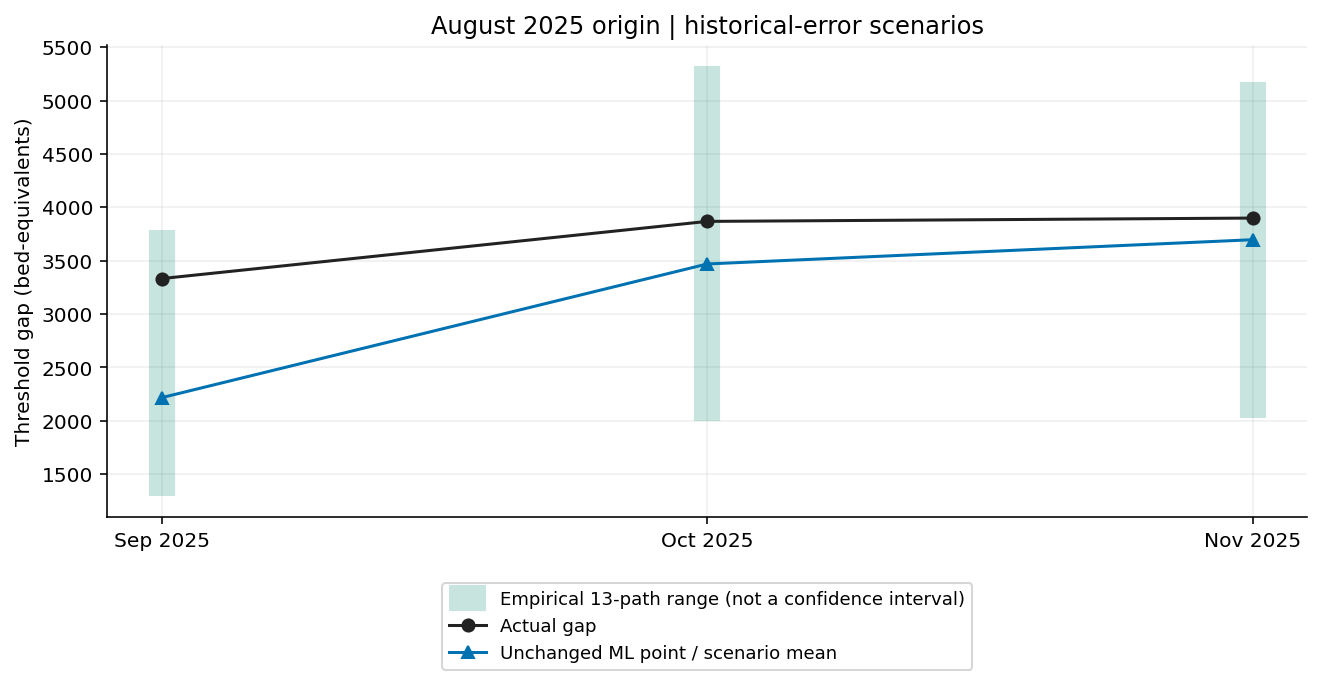

The blue points are identical for policies B and C. Green ranges only describe the 13 centered historical paths; their endpoints are not calibrated coverage bounds. The optimizer receives complete paired paths, not just these extrema.

In [16]:
origin = ORIGINS[0]
august, august_summary = begin_origin(origin)
scenario_plot(origin)

**Persistence: three frozen monthly decisions**, in bed-equivalents.

forecast_month,active,added,removed,shortage,unused
Sep 2025,"1,746.44","1,746.44",0.00,"1,586.33",0.00
Oct 2025,"1,746.44",0.00,0.00,"2,122.00",0.00
Nov 2025,"1,746.44",0.00,0.00,"2,153.11",0.00


**ML point: three frozen monthly decisions**, in bed-equivalents.

forecast_month,active,added,removed,shortage,unused
Sep 2025,"2,217.40","2,217.40",0.00,"1,115.38",0.00
Oct 2025,"3,469.79","1,252.39",0.00,398.65,0.00
Nov 2025,"3,696.88",227.09,0.00,202.67,0.00


**ML uncertainty: three frozen monthly decisions**, in bed-equivalents.

forecast_month,active,added,removed,shortage,unused
Sep 2025,"3,375.77","3,375.77",0.00,0.00,42.99
Oct 2025,"4,388.90","1,013.13",0.00,0.00,520.45
Nov 2025,"4,602.11",213.22,0.00,0.00,702.56


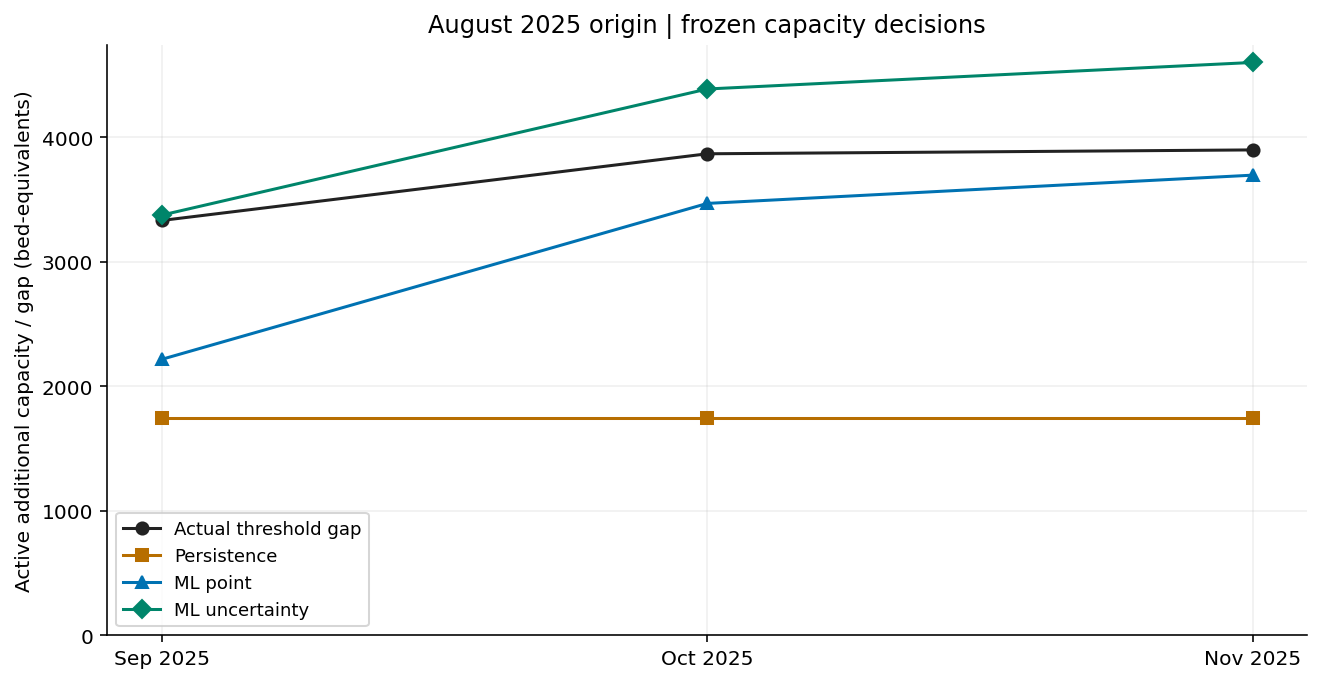

Where the black actual gap exceeds a policy's active capacity, that policy has modeled threshold shortage. Capacity above the black line is unused relative to the threshold. These lines are three decisions fixed at the origin, not reactions to observed outcomes.

In [17]:
decisions_view(origin, august)

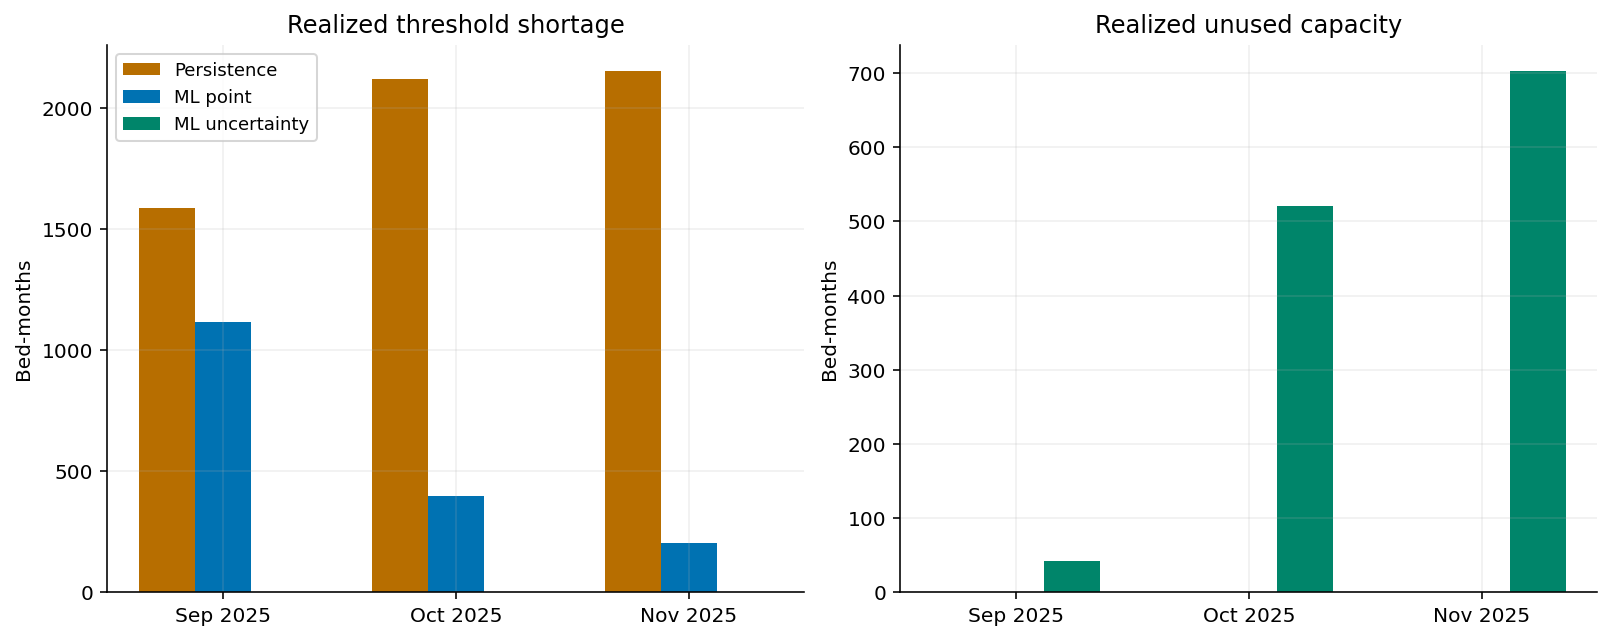

Shortage and unused capacity are recomputed using actual monthly beds after planning. Unused capacity has no separate penalty; any active extra capacity still incurs operating cost. These measures are not patient outcomes.

In [18]:
imbalance_plot(origin, august)

**Persistence: monthly realized modeled costs (GBP)**

forecast_month,operational_cost,shortage_cost,total_realized_cost
Sep 2025,"1,833,766.62","7,931,666.89","9,765,433.51"
Oct 2025,"873,222.20","10,610,000.22","11,483,222.42"
Nov 2025,"873,222.20","10,765,555.78","11,638,777.98"


**ML point: monthly realized modeled costs (GBP)**

forecast_month,operational_cost,shortage_cost,total_realized_cost
Sep 2025,"2,328,271.58","5,576,881.39","7,905,152.96"
Oct 2025,"2,423,709.99","1,993,266.22","4,416,976.21"
Nov 2025,"1,973,343.77","1,013,354.28","2,986,698.05"


**ML uncertainty: monthly realized modeled costs (GBP)**

forecast_month,operational_cost,shortage_cost,total_realized_cost
Sep 2025,"3,544,556.08",0.00,"3,544,556.08"
Oct 2025,"2,751,671.30",0.00,"2,751,671.30"
Nov 2025,"2,418,325.45",0.00,"2,418,325.45"


policy,operational_cost,shortage_cost,total_modeled_cost,deficit_bed_months,unused_bed_months
Persistence,"3,580,211.02","29,307,222.89","32,887,433.91","5,861.44",0.00
ML point,"6,725,325.33","8,583,501.89","15,308,827.22","1,716.70",0.00
ML uncertainty,"8,714,552.83",0.00,"8,714,552.83",0.00,"1,266.00"


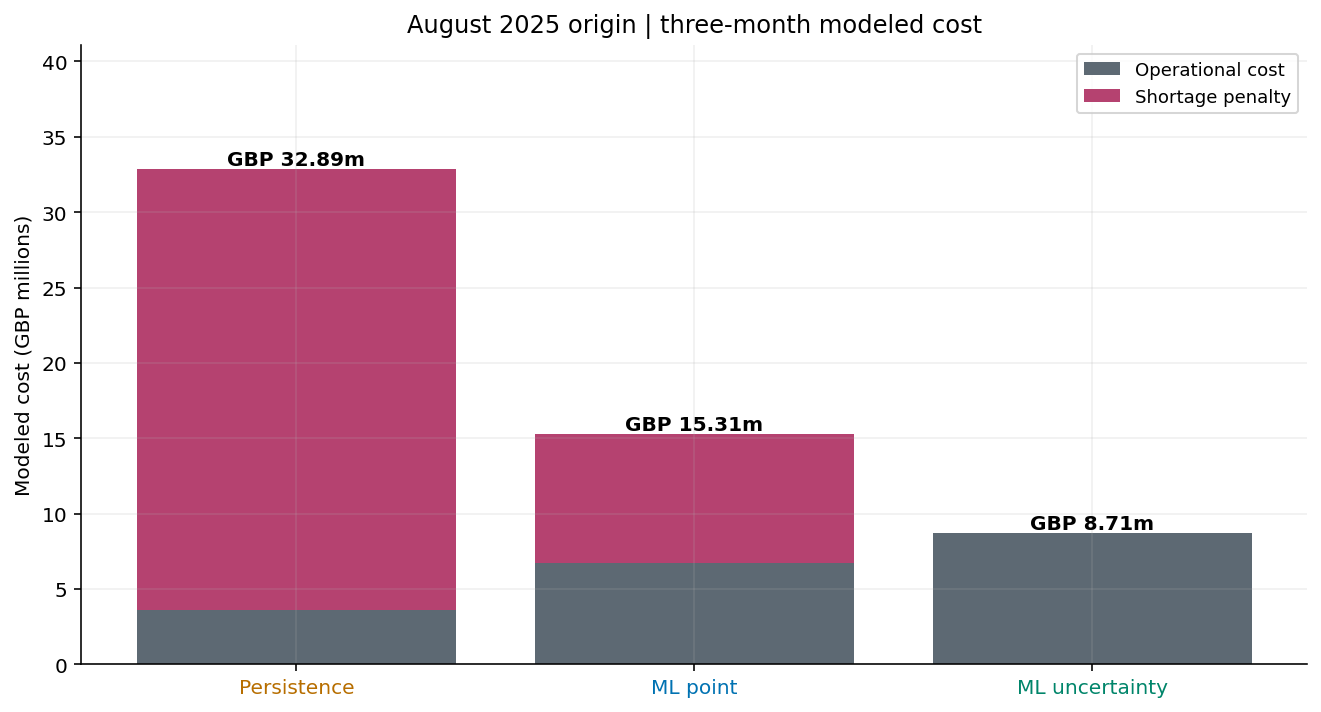

**Uncertainty reduced modeled cost by GBP 6,594,274.40 (43.07% of ML point cost).** The signed reduction B-C is GBP 6,594,274.40.

C minus B operational cost is GBP +1,989,227.49; shortage penalty is GBP -8,583,501.89. Their sum explains the realized total difference, not a change in forecast accuracy.

In September, C added 3,375.77 and removed 0.00, leaving 3,375.77 active versus B's 2,217.40. Actual gap was 3,332.78; C/B shortages were 0.00/1,115.38 and unused capacity 42.99/0.00 bed-equivalents.

In October, C added 1,013.13 and removed 0.00, leaving 4,388.90 active versus B's 3,469.79. Actual gap was 3,868.44; C/B shortages were 0.00/398.65 and unused capacity 520.45/0.00 bed-equivalents.

In November, C added 213.22 and removed 0.00, leaving 4,602.11 active versus B's 3,696.88. Actual gap was 3,899.56; C/B shortages were 0.00/202.67 and unused capacity 702.56/0.00 bed-equivalents.

Both plans were optimal for their own supplied objectives and inherited states. C priced shortage across historical paths; B priced shortage at the mean path. The realized decomposition above explains the observed benefit or loss, not a guarantee that the empirical distribution is correct.

In [19]:
finish_origin(origin, august, august_summary)

## November 2025 origin: December-February
The points expand their upstream forecasting history through November, but the
scenario bank remains frozen at August. Each policy carries its own November end
state into December. None sees December-February outcomes while choosing the plan.

policy,initial_state
Persistence,"1,746.44"
ML point,"3,696.88"
ML uncertainty,"4,602.11"


month,quantity,actual,persistence,ML point (both B and C)
Dec 2025,Available,"101,200","100,906.00","101,296.82"
Jan 2026,Available,"103,272","100,906.00","102,178.75"
Feb 2026,Available,"102,505","100,906.00","102,962.96"
Dec 2025,Occupied,"93,177","94,325.00","94,379.40"
Jan 2026,Occupied,"97,157","94,325.00","96,944.96"
Feb 2026,Occupied,"96,411","94,325.00","97,158.08"


forecast_month,predicted_gap,actual_gap
Dec 2025,"3,569.18","2,330.00"
Jan 2026,"5,537.87","4,680.22"
Feb 2026,"4,990.45","4,618.33"


**Available: empirical scenario minimum, mean and maximum** (beds for components; bed-equivalents for gap).

forecast_month,available_min,available_mean,available_max
Dec 2025,"100,486.25","101,296.82","102,504.13"
Jan 2026,"100,976.49","102,178.75","103,506.77"
Feb 2026,"101,647.60","102,962.96","104,193.25"


**Occupied: empirical scenario minimum, mean and maximum** (beds for components; bed-equivalents for gap).

forecast_month,occupied_min,occupied_mean,occupied_max
Dec 2025,"93,221.90","94,379.40","95,929.37"
Jan 2026,"95,351.71","96,944.96","98,912.22"
Feb 2026,"95,082.03","97,158.08","98,970.57"


**Gap: empirical scenario minimum, mean and maximum** (beds for components; bed-equivalents for gap).

forecast_month,gap_min,gap_mean,gap_max
Dec 2025,"2,650.78","3,569.18","5,140.93"
Jan 2026,"4,065.12","5,537.87","7,387.91"
Feb 2026,"3,322.29","4,990.45","6,467.64"


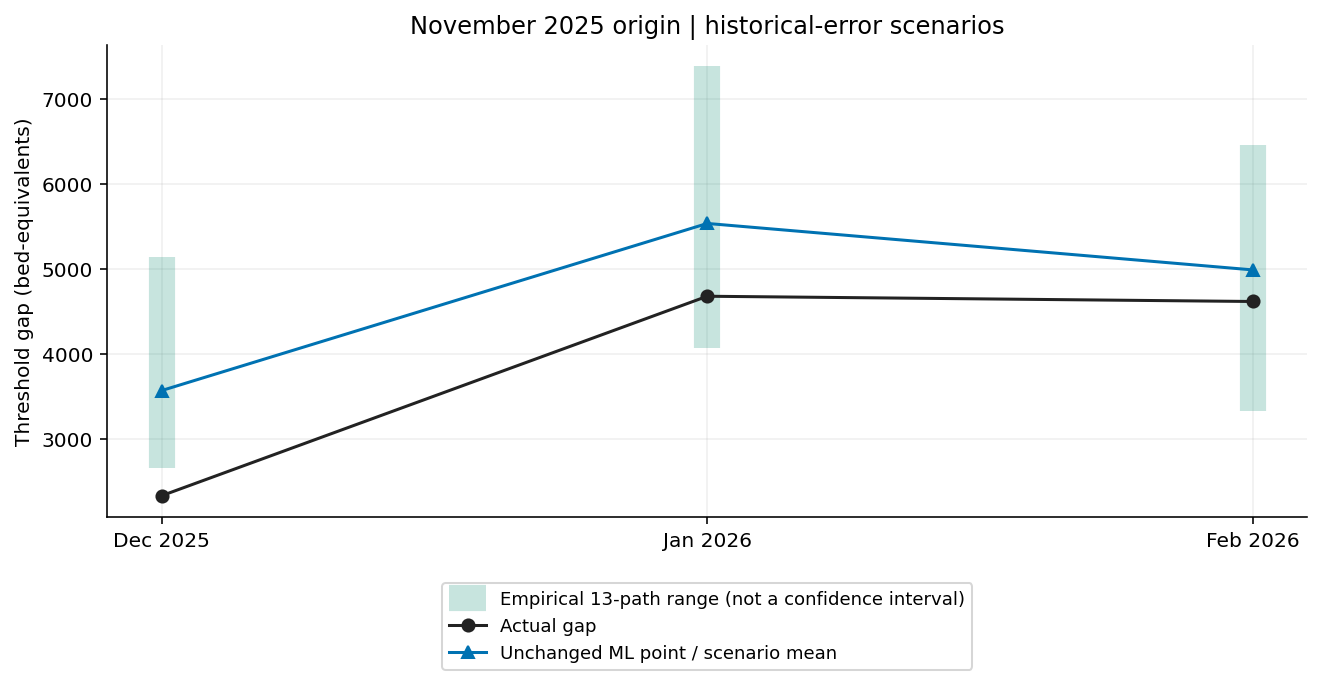

The blue points are identical for policies B and C. Green ranges only describe the 13 centered historical paths; their endpoints are not calibrated coverage bounds. The optimizer receives complete paired paths, not just these extrema.

In [20]:
origin = ORIGINS[1]
november, november_summary = begin_origin(origin)
scenario_plot(origin)

**Persistence: three frozen monthly decisions**, in bed-equivalents.

forecast_month,active,added,removed,shortage,unused
Dec 2025,"3,899.56","2,153.11",0.00,0.00,"1,569.56"
Jan 2026,"3,899.56",0.00,0.00,780.67,0.00
Feb 2026,"3,899.56",0.00,0.00,718.78,0.00


**ML point: three frozen monthly decisions**, in bed-equivalents.

forecast_month,active,added,removed,shortage,unused
Dec 2025,"3,696.88",0.00,0.00,0.00,"1,366.88"
Jan 2026,"5,537.87","1,840.99",0.00,0.00,857.65
Feb 2026,"4,990.45",0.00,547.42,0.00,372.12


**ML uncertainty: three frozen monthly decisions**, in bed-equivalents.

forecast_month,active,added,removed,shortage,unused
Dec 2025,"4,727.54",125.43,0.00,0.00,"2,397.54"
Jan 2026,"6,128.02","1,400.48",0.00,0.00,"1,447.80"
Feb 2026,"6,128.02",0.00,0.00,0.00,"1,509.69"


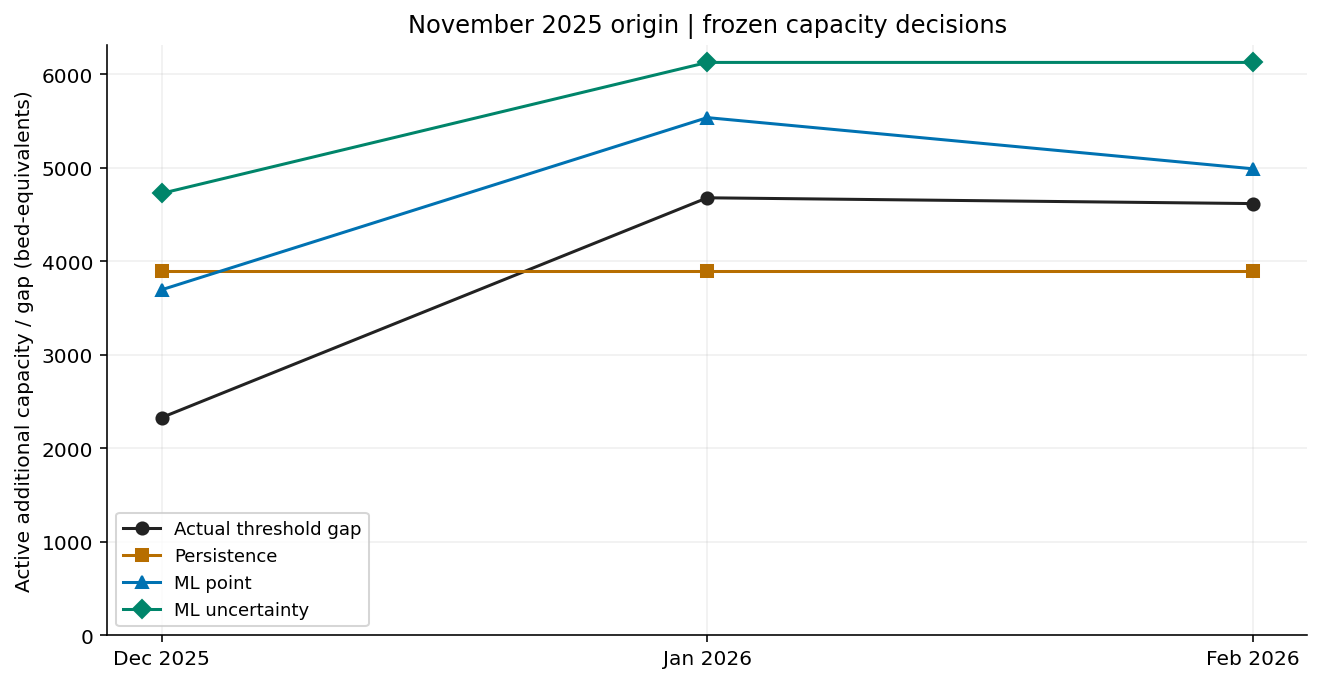

Where the black actual gap exceeds a policy's active capacity, that policy has modeled threshold shortage. Capacity above the black line is unused relative to the threshold. These lines are three decisions fixed at the origin, not reactions to observed outcomes.

In [21]:
decisions_view(origin, november)

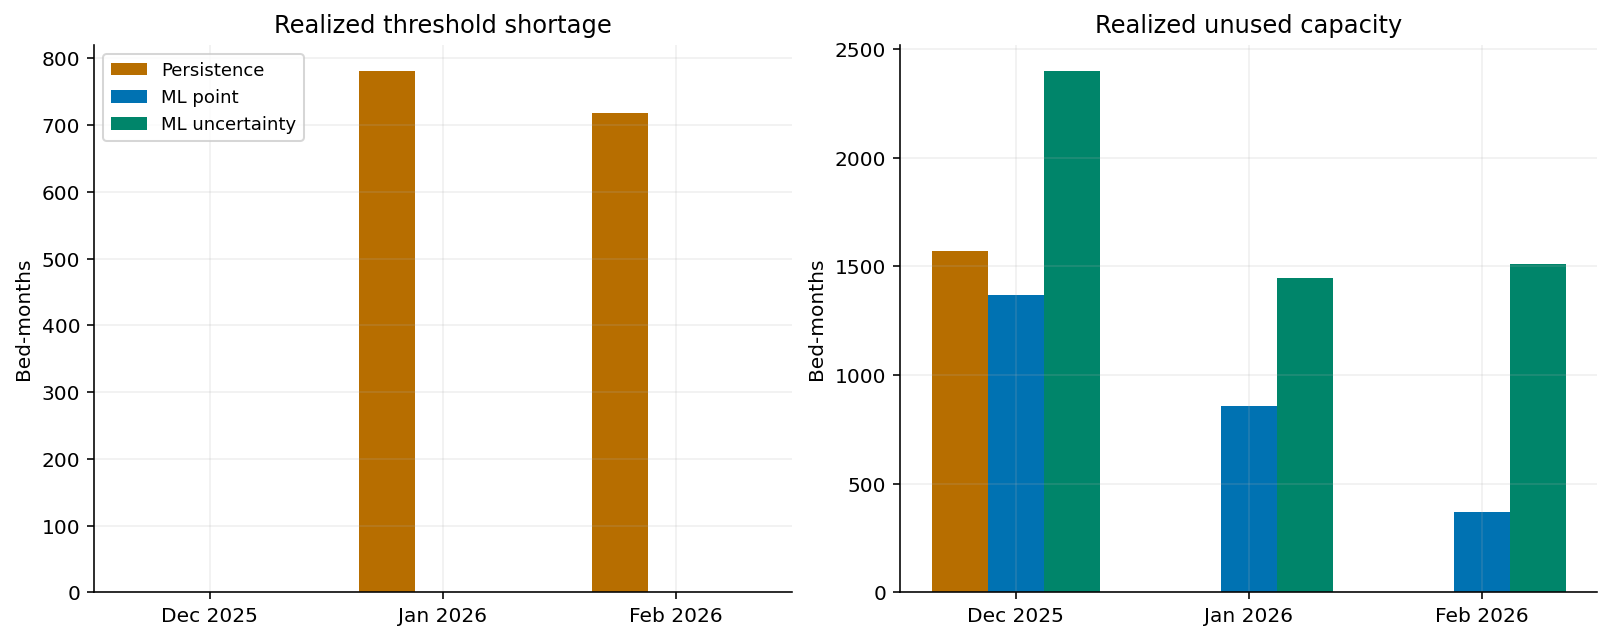

Shortage and unused capacity are recomputed using actual monthly beds after planning. Unused capacity has no separate penalty; any active extra capacity still incurs operating cost. These measures are not patient outcomes.

In [22]:
imbalance_plot(origin, november)

**Persistence: monthly realized modeled costs (GBP)**

forecast_month,operational_cost,shortage_cost,total_realized_cost
Dec 2025,"3,133,988.96",0.00,"3,133,988.96"
Jan 2026,"1,949,777.80","3,903,333.11","5,853,110.91"
Feb 2026,"1,949,777.80","3,593,888.67","5,543,666.47"


**ML point: monthly realized modeled costs (GBP)**

forecast_month,operational_cost,shortage_cost,total_realized_cost
Dec 2025,"1,848,442.35",0.00,"1,848,442.35"
Jan 2026,"3,781,479.23",0.00,"3,781,479.23"
Feb 2026,"2,659,452.68",0.00,"2,659,452.68"


**ML uncertainty: monthly realized modeled costs (GBP)**

forecast_month,operational_cost,shortage_cost,total_realized_cost
Dec 2025,"2,432,757.99",0.00,"2,432,757.99"
Jan 2026,"3,834,273.33",0.00,"3,834,273.33"
Feb 2026,"3,064,010.60",0.00,"3,064,010.60"


policy,operational_cost,shortage_cost,total_modeled_cost,deficit_bed_months,unused_bed_months
Persistence,"7,033,544.56","7,497,221.78","14,530,766.34","1,499.44","1,569.56"
ML point,"8,289,374.25",0.00,"8,289,374.25",0.00,"2,596.66"
ML uncertainty,"9,331,041.93",0.00,"9,331,041.93",0.00,"5,355.03"


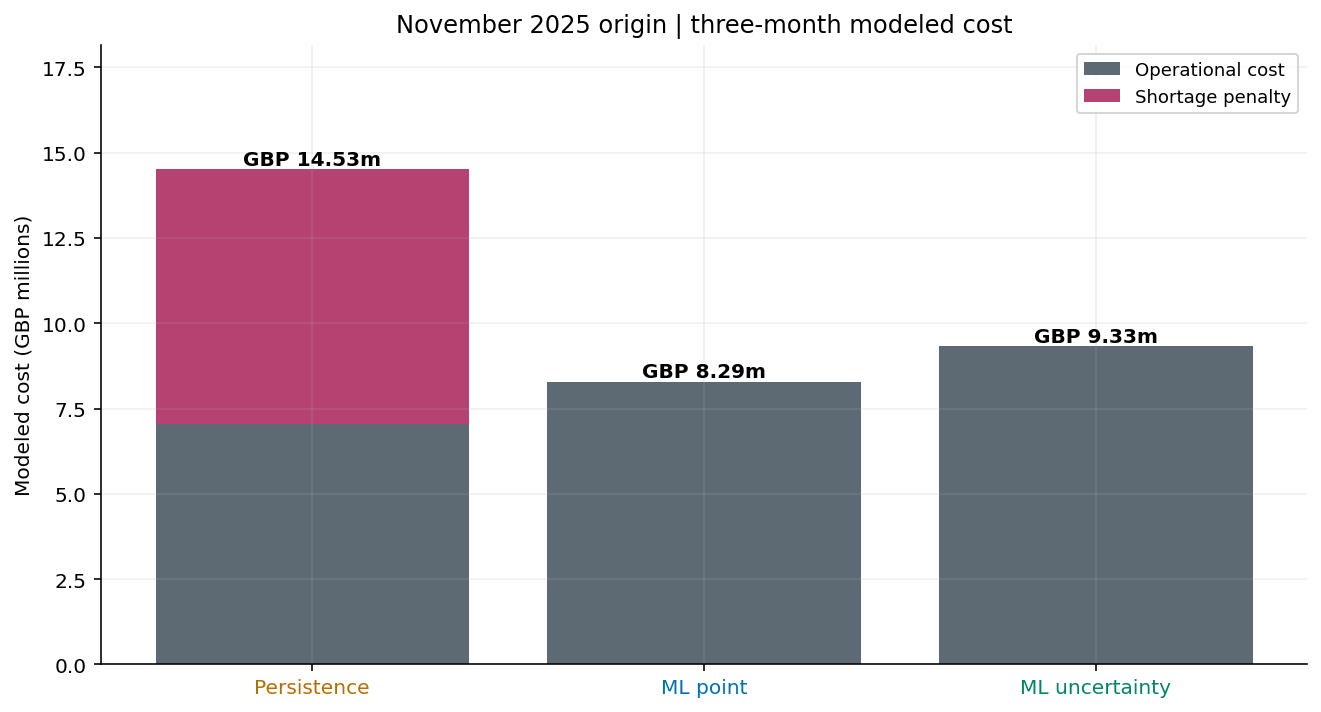

**Uncertainty increased modeled cost by GBP 1,041,667.67 (12.57% of ML point cost).** The signed reduction B-C is GBP -1,041,667.67.

C minus B operational cost is GBP +1,041,667.67; shortage penalty is GBP +0.00. Their sum explains the realized total difference, not a change in forecast accuracy.

In December, C added 125.43 and removed 0.00, leaving 4,727.54 active versus B's 3,696.88. Actual gap was 2,330.00; C/B shortages were 0.00/0.00 and unused capacity 2,397.54/1,366.88 bed-equivalents.

In January, C added 1,400.48 and removed 0.00, leaving 6,128.02 active versus B's 5,537.87. Actual gap was 4,680.22; C/B shortages were 0.00/0.00 and unused capacity 1,447.80/857.65 bed-equivalents.

In February, C added 0.00 and removed 0.00, leaving 6,128.02 active versus B's 4,990.45. Actual gap was 4,618.33; C/B shortages were 0.00/0.00 and unused capacity 1,509.69/372.12 bed-equivalents.

Both plans were optimal for their own supplied objectives and inherited states. C priced shortage across historical paths; B priced shortage at the mean path. The realized decomposition above explains the observed benefit or loss, not a guarantee that the empirical distribution is correct.

Inherited states differed: B 3,696.88, C 4,602.11. This block is part of connected policy trajectories, not an equal-initial-state ablation.

In [23]:
finish_origin(origin, november, november_summary)

## February 2026 origin: March-May
The deterministic experiment's smaller ML gap MAE did not imply smaller costs in
this block: the frozen plan removed capacity before April/May shortages appeared.
Here we test whether the same point decline plus the unchanged historical error
bank changes those decisions and their costs. No new error observations enter the bank.

policy,initial_state
Persistence,"3,899.56"
ML point,"4,990.45"
ML uncertainty,"6,128.02"


month,quantity,actual,persistence,ML point (both B and C)
Mar 2026,Available,"101,328","102,505.00","102,845.81"
Apr 2026,Available,"100,758","102,505.00","102,335.72"
May 2026,Available,"100,396","102,505.00","102,017.52"
Mar 2026,Occupied,"94,681","96,411.00","96,271.97"
Apr 2026,Occupied,"93,869","96,411.00","94,969.09"
May 2026,Occupied,"93,604","96,411.00","94,140.45"


forecast_month,predicted_gap,actual_gap
Mar 2026,"4,123.04","3,873.11"
Apr 2026,"3,185.49","3,540.89"
May 2026,"2,582.98","3,608.44"


**Available: empirical scenario minimum, mean and maximum** (beds for components; bed-equivalents for gap).

forecast_month,available_min,available_mean,available_max
Mar 2026,"102,035.24","102,845.81","104,053.12"
Apr 2026,"101,133.46","102,335.72","103,663.74"
May 2026,"100,702.16","102,017.52","103,247.81"


**Occupied: empirical scenario minimum, mean and maximum** (beds for components; bed-equivalents for gap).

forecast_month,occupied_min,occupied_mean,occupied_max
Mar 2026,"95,114.47","96,271.97","97,821.94"
Apr 2026,"93,375.84","94,969.09","96,936.35"
May 2026,"92,064.40","94,140.45","95,952.95"


**Gap: empirical scenario minimum, mean and maximum** (beds for components; bed-equivalents for gap).

forecast_month,gap_min,gap_mean,gap_max
Mar 2026,"3,204.64","4,123.04","5,694.79"
Apr 2026,"1,712.74","3,185.49","5,035.53"
May 2026,914.81,"2,582.98","4,060.17"


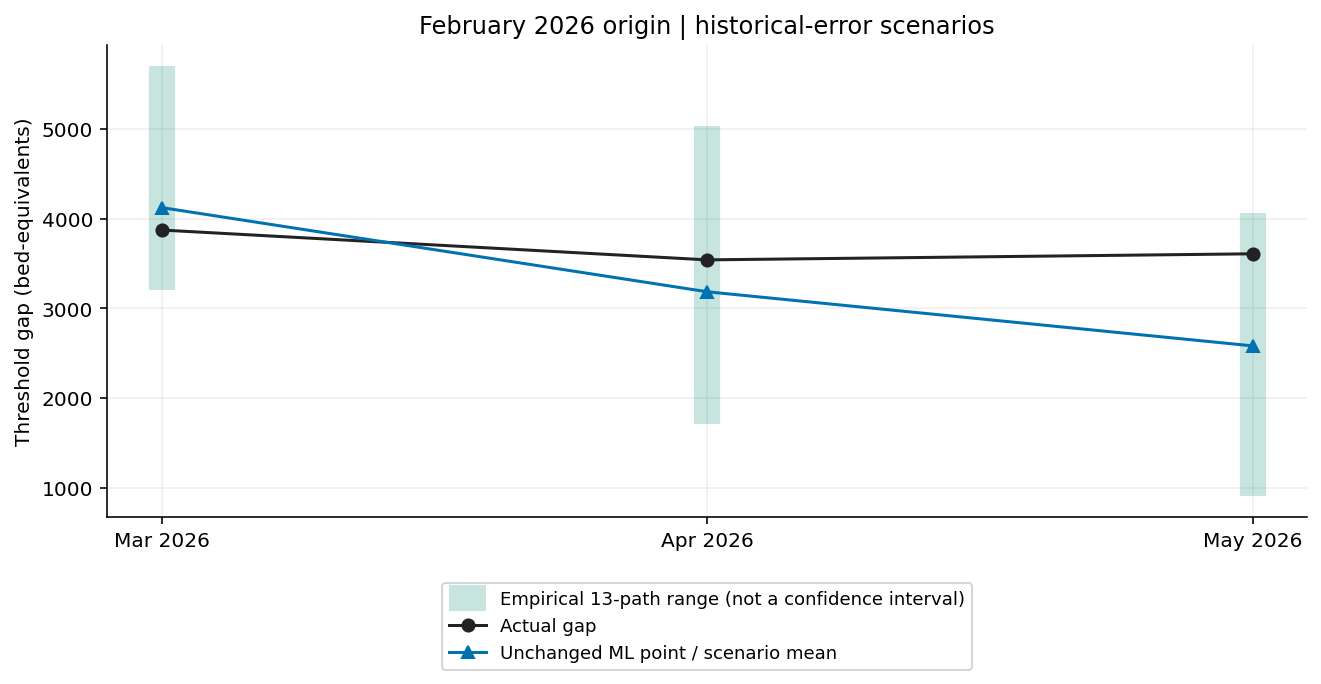

The blue points are identical for policies B and C. Green ranges only describe the 13 centered historical paths; their endpoints are not calibrated coverage bounds. The optimizer receives complete paired paths, not just these extrema.

In [24]:
origin = ORIGINS[2]
february, february_summary = begin_origin(origin)
scenario_plot(origin)

**Persistence: three frozen monthly decisions**, in bed-equivalents.

forecast_month,active,added,removed,shortage,unused
Mar 2026,"4,618.33",718.78,0.00,0.00,745.22
Apr 2026,"4,618.33",0.00,0.00,0.00,"1,077.44"
May 2026,"4,618.33",0.00,0.00,0.00,"1,009.89"


**ML point: three frozen monthly decisions**, in bed-equivalents.

forecast_month,active,added,removed,shortage,unused
Mar 2026,"4,123.04",0.00,867.41,0.00,249.93
Apr 2026,"3,185.49",0.00,937.56,355.40,0.00
May 2026,"2,582.98",0.00,602.51,"1,025.46",0.00


**ML uncertainty: three frozen monthly decisions**, in bed-equivalents.

forecast_month,active,added,removed,shortage,unused
Mar 2026,"5,281.41",0.00,846.61,0.00,"1,408.30"
Apr 2026,"4,104.59",0.00,"1,176.81",0.00,563.70
May 2026,"4,060.17",0.00,44.43,0.00,451.72


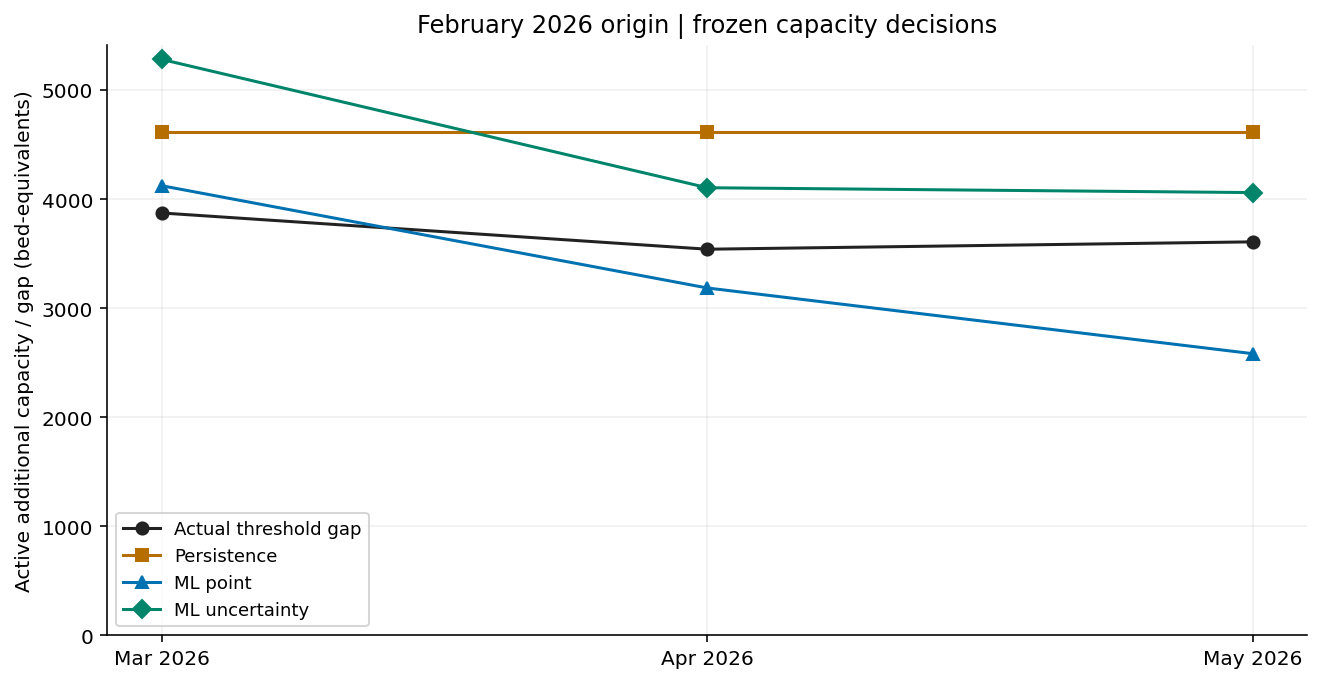

Where the black actual gap exceeds a policy's active capacity, that policy has modeled threshold shortage. Capacity above the black line is unused relative to the threshold. These lines are three decisions fixed at the origin, not reactions to observed outcomes.

In [25]:
decisions_view(origin, february)

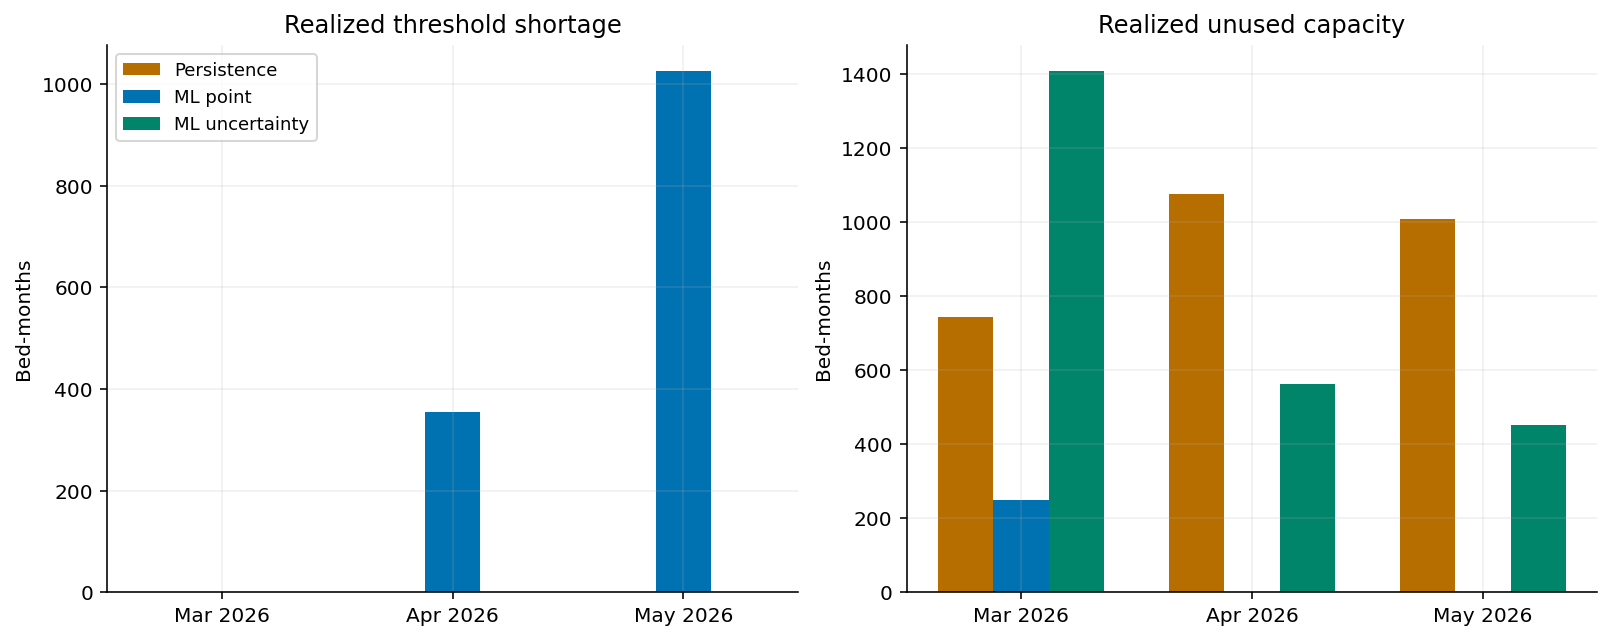

Shortage and unused capacity are recomputed using actual monthly beds after planning. Unused capacity has no separate penalty; any active extra capacity still incurs operating cost. These measures are not patient outcomes.

In [26]:
imbalance_plot(origin, february)

**Persistence: monthly realized modeled costs (GBP)**

forecast_month,operational_cost,shortage_cost,total_realized_cost
Mar 2026,"2,704,494.40",0.00,"2,704,494.40"
Apr 2026,"2,309,166.65",0.00,"2,309,166.65"
May 2026,"2,309,166.65",0.00,"2,309,166.65"


**ML point: monthly realized modeled costs (GBP)**

forecast_month,operational_cost,shortage_cost,total_realized_cost
Mar 2026,"2,321,744.67",0.00,"2,321,744.67"
Apr 2026,"1,874,009.33","1,777,018.44","3,651,027.78"
May 2026,"1,472,241.49","5,127,323.72","6,599,565.22"


**ML uncertainty: monthly realized modeled costs (GBP)**

forecast_month,operational_cost,shortage_cost,total_realized_cost
Mar 2026,"2,894,687.81",0.00,"2,894,687.81"
Apr 2026,"2,405,340.63",0.00,"2,405,340.63"
May 2026,"2,043,411.17",0.00,"2,043,411.17"


policy,operational_cost,shortage_cost,total_modeled_cost,deficit_bed_months,unused_bed_months
Persistence,"7,322,827.70",0.00,"7,322,827.70",0.00,"2,832.56"
ML point,"5,667,995.50","6,904,342.17","12,572,337.66","1,380.87",249.93
ML uncertainty,"7,343,439.62",0.00,"7,343,439.62",0.00,"2,423.72"


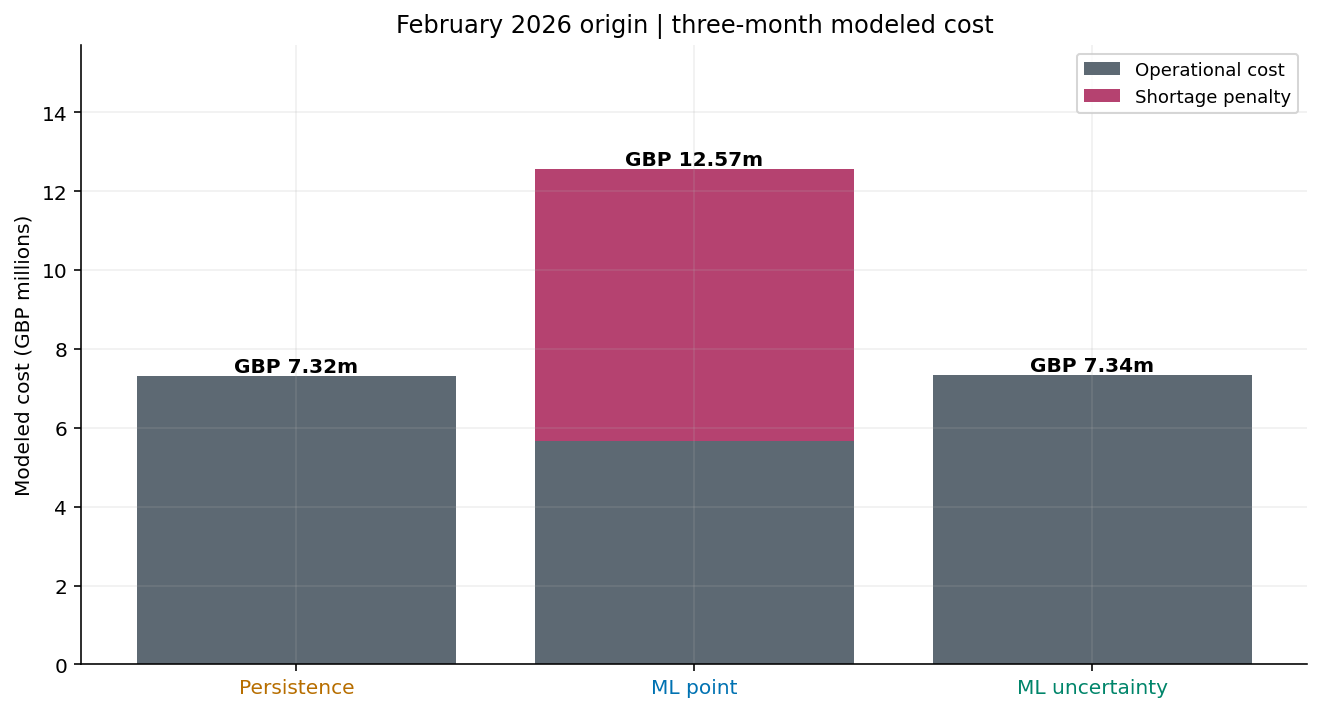

**Uncertainty reduced modeled cost by GBP 5,228,898.04 (41.59% of ML point cost).** The signed reduction B-C is GBP 5,228,898.04.

C minus B operational cost is GBP +1,675,444.12; shortage penalty is GBP -6,904,342.17. Their sum explains the realized total difference, not a change in forecast accuracy.

In March, C added 0.00 and removed 846.61, leaving 5,281.41 active versus B's 4,123.04. Actual gap was 3,873.11; C/B shortages were 0.00/0.00 and unused capacity 1,408.30/249.93 bed-equivalents.

In April, C added 0.00 and removed 1,176.81, leaving 4,104.59 active versus B's 3,185.49. Actual gap was 3,540.89; C/B shortages were 0.00/355.40 and unused capacity 563.70/0.00 bed-equivalents.

In May, C added 0.00 and removed 44.43, leaving 4,060.17 active versus B's 2,582.98. Actual gap was 3,608.44; C/B shortages were 0.00/1,025.46 and unused capacity 451.72/0.00 bed-equivalents.

Both plans were optimal for their own supplied objectives and inherited states. C priced shortage across historical paths; B priced shortage at the mean path. The realized decomposition above explains the observed benefit or loss, not a guarantee that the empirical distribution is correct.

Inherited states differed: B 4,990.45, C 6,128.02. This block is part of connected policy trajectories, not an equal-initial-state ablation.

In [27]:
finish_origin(origin, february, february_summary)

## Pooled nine-month results
Sum realized monthly costs, not scenario costs, for the primary result. Expected
objective values belong to the optimizer's input distribution, not observed outcomes.
Pooled coverage is one minus total shortage divided by total required capacity;
it is not the arithmetic average of block percentages and is not a patient service measure.

period,persistence_cost,ML_point_cost,ML_uncertainty_cost,uncertainty_cost_reduction,percentage_reduction
August 2025,"32,887,433.91","15,308,827.22","8,714,552.83","6,594,274.40",43.07
November 2025,"14,530,766.34","8,289,374.25","9,331,041.93","-1,041,667.67",-12.57
February 2026,"7,322,827.70","12,572,337.66","7,343,439.62","5,228,898.04",41.59
Overall: September-May,"54,741,027.95","36,170,539.14","25,389,034.37","10,781,504.76",29.81


policy,operational_cost,shortage_cost,deficit_bed_months,unused_bed_months,capacity_coverage
ML point,"20,682,695.084","15,487,844.056","3,097.569","2,846.586",0.997
ML uncertainty,"25,389,034.374",0.000,0.000,"9,044.755",1.000
Persistence,"17,936,583.282","36,804,444.667","7,360.889","4,402.111",0.992


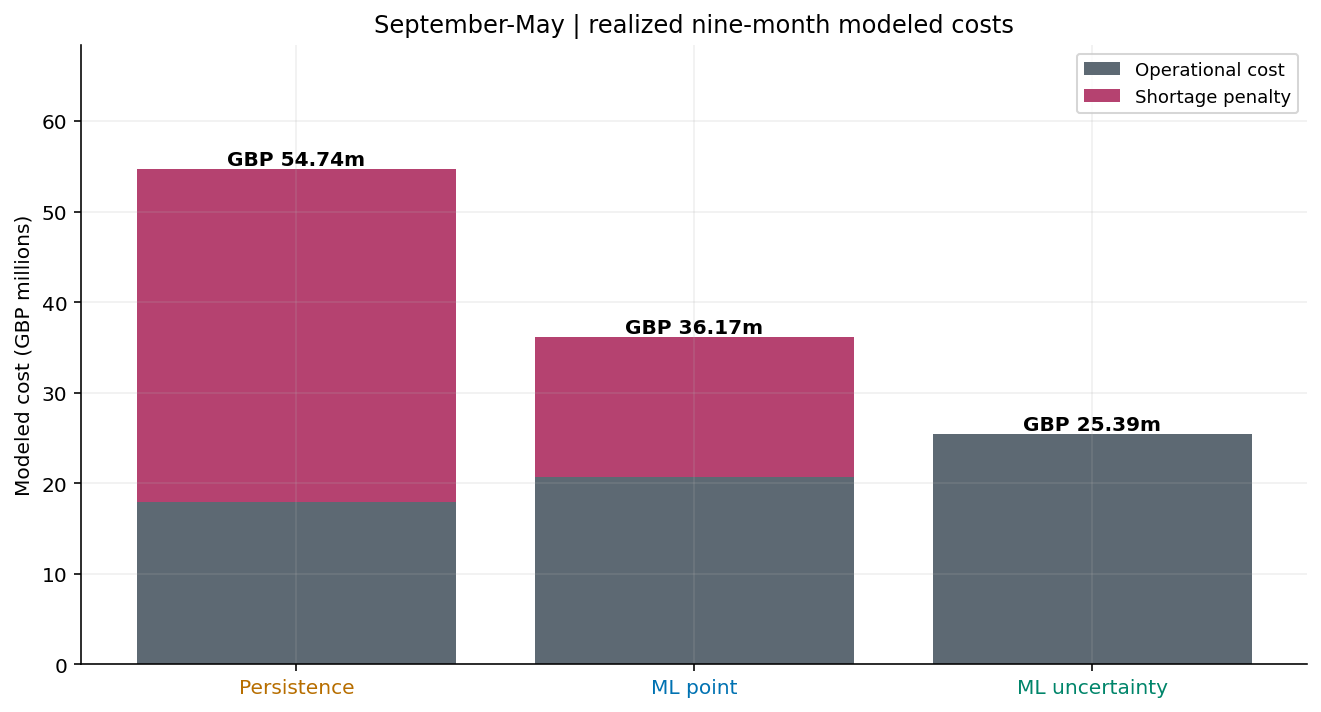

**ML uncertainty had lower nine-month modeled cost than ML point planning by GBP 10,781,504.76 (29.81%).** The per-origin table preserves gains and losses. This evaluates the entire connected policy trajectory; it is not evidence that uncertainty always helps, nor an NHS cash saving.

In [28]:
decisions = pd.concat(plans, ignore_index=True)
realized = pd.concat(outcomes, ignore_index=True)
block_summary = pd.DataFrame(blocks)
pooled = pd.DataFrame([{"policy": p, **u.summarize(g)} for p,g in realized.groupby("policy")])
comparisons = pd.DataFrame(comparison_rows + [u.cost_comparison(pooled, "Overall: September-May")])
table(comparisons)
table(pooled[["policy", "operational_cost", "shortage_cost", "deficit_bed_months", "unused_bed_months", "capacity_coverage"]].replace({"policy": LABELS}), 3)
cost_plot(pooled, "nine_month_costs.png", "September-May | realized nine-month modeled costs")
overall = comparisons.iloc[-1]
direction = "lower" if overall.uncertainty_cost_reduction >= 0 else "higher"
pooled_note = (f"**ML uncertainty had {direction} nine-month modeled cost than ML point planning by GBP "
              f"{abs(overall.uncertainty_cost_reduction):,.2f} ({abs(overall.percentage_reduction):.2f}%).** "
              "The per-origin table preserves gains and losses. This evaluates the entire connected policy trajectory; "
              "it is not evidence that uncertainty always helps, nor an NHS cash saving.")
display(Markdown(pooled_note))
for frame, name in [(decisions, "monthly_decisions"), (realized, "monthly_realized_results"),
                    (block_summary, "per_origin_policy_summary"), (pooled, "pooled_policy_summary"),
                    (comparisons, "uncertainty_cost_comparison"), (pd.DataFrame(solve_records), "primary_solver_audit"),
                    (pd.concat(scenario_accounting, ignore_index=True), "scenario_solution_accounting"),
                    (pd.DataFrame(figures), "figure_inventory"), (pd.DataFrame(figure_values), "figure_source_values")]:
    save(frame, name)

## Verification
Numerical cost reconciliation uses 1e-7 GBP for stored deterministic results.
Physical constraints use 0.001 bed-equivalents, matching the authoritative realized
evaluator's sub-0.001 balance cutoff and CBC text precision. Independent expected
objective checks allow 2 GBP: 0.001 times the effective maximum marginal coefficient
bounds much larger error, and no displayed/policy-level substantive difference is hidden.
Tests and any synthetic verification solves are reported separately from nine primary solves.

In [29]:
audit = pd.DataFrame(solve_records)
check("Exactly nine primary solves", len(audit) == 9 and audit.groupby(["policy", "forecast_origin"]).size().eq(1).all())
check("All primary solves Optimal", audit.solver_status.eq("Optimal").all())
check("Exactly three fixed decisions per solve", len(decisions) == 27 and decisions.groupby(["policy", "forecast_origin"]).size().eq(3).all())
check("No repeated implemented month", not decisions.duplicated(["policy", "forecast_month"]).any())
check("No CVaR", not audit.loc[audit.policy == C, "cvar_enabled"].any() and audit.loc[audit.policy == C, "cvar_weight"].eq(0).all())
check("One frozen bank for all origins", audit.loc[audit.policy == C, "residual_bank_sha256"].eq(bank_hash).all()
      and bank_hash == hashlib.sha256(bank.to_csv(index=False).encode()).hexdigest())
for policy in POLICIES:
    g = decisions[decisions.policy == policy].sort_values("forecast_month")
    check(f"Nine exact evaluation months {policy}", pd.DatetimeIndex(g.forecast_month).equals(pd.date_range("2025-09-01", "2026-05-01", freq="MS")))
    check(f"Separate continuous state carry {policy}", np.allclose(g.initial_capacity_for_month, np.r_[0., g.additional_capacity_active.to_numpy()[:-1]], atol=TOL, rtol=0))
check("Transitions independently verified", np.max(abs(decisions.additional_capacity_active - decisions.initial_capacity_for_month - decisions.capacity_added + decisions.capacity_removed)) < TOL)
for column, limit in [("additional_capacity_active", 15000), ("capacity_added", 5000), ("capacity_removed", 5000)]:
    check("Physical bounds " + column, decisions[column].between(-TOL, limit+TOL).all())
check("No hidden outcome planning flags", not decisions.uses_future_actuals.any()
      and (decisions.forecast_origin < decisions.forecast_month).all())
for origin in ORIGINS:
    check(f"Identical B/C point forecasts {origin:%Y-%m}", point_paths[origin,B].equals(point_paths[origin,C]))
    subset = decisions[(decisions.forecast_origin == origin) & (decisions.policy == C)].sort_values("forecast_month")
    point = point_paths[origin,B]
    check(f"Solver mean inputs preserve ML points {origin:%Y-%m}", np.allclose(subset.available_capacity_input, point[A], atol=1e-8, rtol=0)
          and np.allclose(subset.occupied_demand_input, point[O], atol=1e-8, rtol=0))
    accounting = pd.concat(scenario_accounting).query("forecast_origin == @origin")
    check(f"Scenario decisions shared {origin:%Y-%m}", accounting.groupby("forecast_month").additional_capacity_active.nunique().eq(1).all())
    for date, g in accounting.groupby("forecast_month"):
        x = subset.set_index("forecast_month").loc[date, "additional_capacity_active"]
        check(f"Shared x matches implementation {origin:%Y-%m} {date:%Y-%m}", np.allclose(g.additional_capacity_active, x, atol=TOL, rtol=0))
    exact_short = np.maximum(accounting.occupied_demand/RHO-accounting.available_capacity-accounting.additional_capacity_active, 0.)
    check(f"Scenario shortages/feasibility {origin:%Y-%m}", np.allclose(accounting.scenario_shortage, exact_short, atol=TOL, rtol=0)
          and accounting.capacity_balance_residual.abs().max() < TOL)
    independent_expected = (500*subset.additional_capacity_active+550*subset.capacity_added+300*subset.capacity_removed).sum() + (5000*exact_short*accounting.probability).sum()
    objective = audit[(audit.policy == C) & (audit.forecast_origin == origin)].objective_value.iloc[0]
    check(f"Expected objective independent arithmetic {origin:%Y-%m}", abs(independent_expected-objective) < 2., abs(independent_expected-objective))

In [30]:
available_actual = actuals.loc[realized.forecast_month, A].to_numpy()
occupied_actual = actuals.loc[realized.forecast_month, O].to_numpy()
shortage = np.maximum(occupied_actual/RHO-available_actual-realized.additional_capacity_active, 0.)
unused = np.maximum(available_actual+realized.additional_capacity_active-occupied_actual/RHO, 0.)
shortage = np.where(shortage < TOL, 0., shortage)
unused = np.where(unused < TOL, 0., unused)
operational = 500*realized.additional_capacity_active+550*realized.capacity_added+300*realized.capacity_removed
check("Workbook-based shortage arithmetic", np.allclose(shortage, realized.realized_shortage_bed_months, atol=1e-8, rtol=0))
check("Workbook-based unused arithmetic", np.allclose(unused, realized.realized_unused_bed_months, atol=1e-8, rtol=0))
check("Independent monthly operating costs", np.allclose(operational, realized.operational_cost, atol=1e-7, rtol=0))
check("Independent monthly realized costs", np.allclose(operational+5000*shortage, realized.total_realized_cost, atol=1e-7, rtol=0))
for _, block in block_summary.iterrows():
    g = realized[(realized.policy == block.policy) & (realized.forecast_origin == block.forecast_origin)]
    for col, source in [("total_modeled_cost", "total_realized_cost"), ("operational_cost", "operational_cost"),
                        ("shortage_cost", "shortage_cost"), ("deficit_bed_months", "realized_shortage_bed_months"),
                        ("unused_bed_months", "realized_unused_bed_months")]:
        check(f"Monthly to block {block.policy} {block.forecast_origin:%Y-%m} {col}", abs(g[source].sum()-block[col]) < 1e-7)
for _, row in pooled.iterrows():
    g = block_summary[block_summary.policy == row.policy]
    for col in ["total_modeled_cost", "operational_cost", "shortage_cost", "deficit_bed_months", "unused_bed_months"]:
        check(f"Direct three-block sum equals pooled {row.policy} {col}", abs(g[col].sum()-row[col]) < 1e-7)
    r = realized[realized.policy == row.policy]
    check(f"Pooled weighted coverage {row.policy}", abs(row.capacity_coverage-(1-r.realized_shortage_bed_months.sum()/r.actual_required_capacity.sum())) < 1e-12)
check("Signed reduction arithmetic", np.allclose(comparisons.uncertainty_cost_reduction, comparisons.ML_point_cost-comparisons.ML_uncertainty_cost))
check("Percentage denominator is ML point", np.allclose(comparisons.percentage_reduction, 100*comparisons.uncertainty_cost_reduction/comparisons.ML_point_cost))
check("Locked file unchanged", digest(FD / "frozen_forecast_paths.csv") == protected[FD / "frozen_forecast_paths.csv"])
changed = [str(p.relative_to(ROOT)) for p,h in protected.items() if not p.exists() or digest(p) != h]
check("Existing inputs preserved", not changed, changed)
test_results = json.loads((OUT / "regression_test_results.json").read_text(encoding="utf-8"))
check("Relevant regression and new uncertainty tests passed", test_results["successful"], test_results["tests_run"])
display(Markdown(f"**{test_results['tests_run']} tests passed**, including new future-poison, pairing, centering, "
                "domain-rejection and zero-dispersion equivalence checks. Two old-notebook execution tests were deliberately excluded "
                "because they may overwrite authoritative outputs. "
                f"The tests performed **{len(test_results['additional_verification_solves'])} separate verification solves**, "
                "not included in the nine primary solves."))
save(pd.DataFrame(test_results["additional_verification_solves"]), "additional_verification_solver_audit")
if (OUT / "presentation_reexecution_solver_audit.csv").exists():
    repeat_audit = pd.read_csv(OUT / "presentation_reexecution_solver_audit.csv")
    display(Markdown(f"A prior complete execution supplied **{len(repeat_audit)} additional reproducibility-verification solves** "
                    "before a legend-only presentation adjustment. These are logged separately; "
                    "the primary experiment still has one solve per policy/origin, nine in total. "
                    "Post-execution verification compares the repeated numerical outputs without changing the design."))
save(pd.DataFrame(checks), "verification_checks")
save(pd.DataFrame(reconciliations), "deterministic_reconciliation")
table(pd.DataFrame(checks))
display(Markdown(f"**{len(checks)} calculation checks passed.** External execution verification also checks every inline PNG against its saved bytes, "
                "checks nonblank images, runs the selected regression tests and records visual inspection."))

**62 tests passed**, including new future-poison, pairing, centering, domain-rejection and zero-dispersion equivalence checks. Two old-notebook execution tests were deliberately excluded because they may overwrite authoritative outputs. The tests performed **5 separate verification solves**, not included in the nine primary solves.

A prior complete execution supplied **9 additional reproducibility-verification solves** before a legend-only presentation adjustment. These are logged separately; the primary experiment still has one solve per policy/origin, nine in total. Post-execution verification compares the repeated numerical outputs without changing the design.

check,status,detail
Locked model assignments,PASS,
Locked selection precedes test,PASS,
Exact origin grid,PASS,
Exact locked key count,PASS,
Exact point months 2025-08 frozen_persistence,PASS,
Persistence repeats origin observation 2025-08,PASS,
Workbook actuals 2025-08 frozen_persistence g_and_a_beds_available,PASS,
Workbook actuals 2025-08 frozen_persistence g_and_a_beds_occupied,PASS,
Exact point months 2025-08 frozen_locked_ml,PASS,
Workbook actuals 2025-08 frozen_locked_ml g_and_a_beds_available,PASS,


**218 calculation checks passed.** External execution verification also checks every inline PNG against its saved bytes, checks nonblank images, runs the selected regression tests and records visual inspection.

## Interpretation and limits
Historical errors may not represent future errors, particularly with only 13
overlapping paths and changing bed patterns. Errors at different horizons and
targets are dependent; preserving empirical paths does not make them independent.
The locked model identities were selected using development outcomes also represented
in calibration. These are chronological fixed-model residuals, not nested-selection
or independent calibration errors. No September 2025-May 2026 outcomes enter the bank.

The nine evaluation outcomes have already been examined. This exploratory comparison
does not restore a pristine sealed test or justify tuning assumptions to obtain a win.
Costs, limits and the 90% threshold are illustrative and unvalidated. Publication-time
availability and historical data vintages remain unresolved: origin month means an
admitted observation cutoff, not proof the monthly return was already published then.
The operational boundary between additional capacity and published available beds
(which may already include escalation capacity) also remains unresolved.

Modeled shortage and coverage are threshold measures, not patient outcomes. Surplus
is not necessarily waste in clinical practice. Three connected blocks provide limited
evidence; their inherited states differ. No real NHS cash saving is established.
The short horizon has no terminal value and may encourage end-of-block reductions.
Centering deliberately removes historical bias; it does not claim the true future
forecast errors have zero mean. There are no promised interval coverage levels.

In [31]:
def markdown_table(frame):
    def value(v):
        return f"{v:,.2f}" if isinstance(v, (float, np.floating)) else str(v)
    return "\n".join(["| " + " | ".join(frame.columns) + " |", "| " + " | ".join(["---"]*len(frame.columns)) + " |"]
                     + ["| " + " | ".join(map(value,row)) + " |" for row in frame.itertuples(index=False, name=None)])
cheat = "# Presenter cheat sheet: historical-error uncertainty\n\n" + pooled_note + "\n\n" + markdown_table(comparisons)
cheat += "\n\n" + "\n\n".join(narratives)
cheat += """\n\n## What to say out loud
The same ML forecasts feed both ML policies. The new optimizer prices shortage
over 13 equally weighted, horizon-centered paired historical paths. Its scenario
means equal the ML points; there is no bias correction, clipping, CQR or CVaR.
All three decisions stay frozen, and each policy carries its own state between blocks.
The principal signed reduction is ML point cost minus ML uncertainty cost.
A negative value is a cost increase, never a saving. Accuracy alone cannot predict
decision value because shortages are asymmetric and state changes have costs.

## Limits that travel with the numbers
Small overlapping historical-error sample; fixed model identities conditioned on
development selection; nine already-inspected monthly national aggregate outcomes;
exploratory comparison, not a prospective trial. Historical errors may not recur.
Costs, limits and the 90% threshold are illustrative. Publication/vintage timing and
the boundary for extra capacity are unresolved. No real NHS cash savings or patient
benefits are established. Scenario ranges are not confidence or coverage guarantees.
"""
(OUT / "presenter_cheat_sheet.md").write_text(cheat, encoding="utf-8")
display(Markdown(pooled_note))
display(Markdown("Read the origin's scenario, capacity, imbalance and cost plots together. "
                "The detailed monthly CSVs and `presenter_cheat_sheet.md` retain both positive and negative results."))

**ML uncertainty had lower nine-month modeled cost than ML point planning by GBP 10,781,504.76 (29.81%).** The per-origin table preserves gains and losses. This evaluates the entire connected policy trajectory; it is not evidence that uncertainty always helps, nor an NHS cash saving.

Read the origin's scenario, capacity, imbalance and cost plots together. The detailed monthly CSVs and `presenter_cheat_sheet.md` retain both positive and negative results.

## August 2025 origin

**Frozen planning months: September–November 2025.**

Policy,Total modeled cost (GBP)
Without ML — Persistence,"£32,887,433.91"
With ML — Point forecasts,"£15,308,827.22"
With ML + uncertainty,"£8,714,552.83"


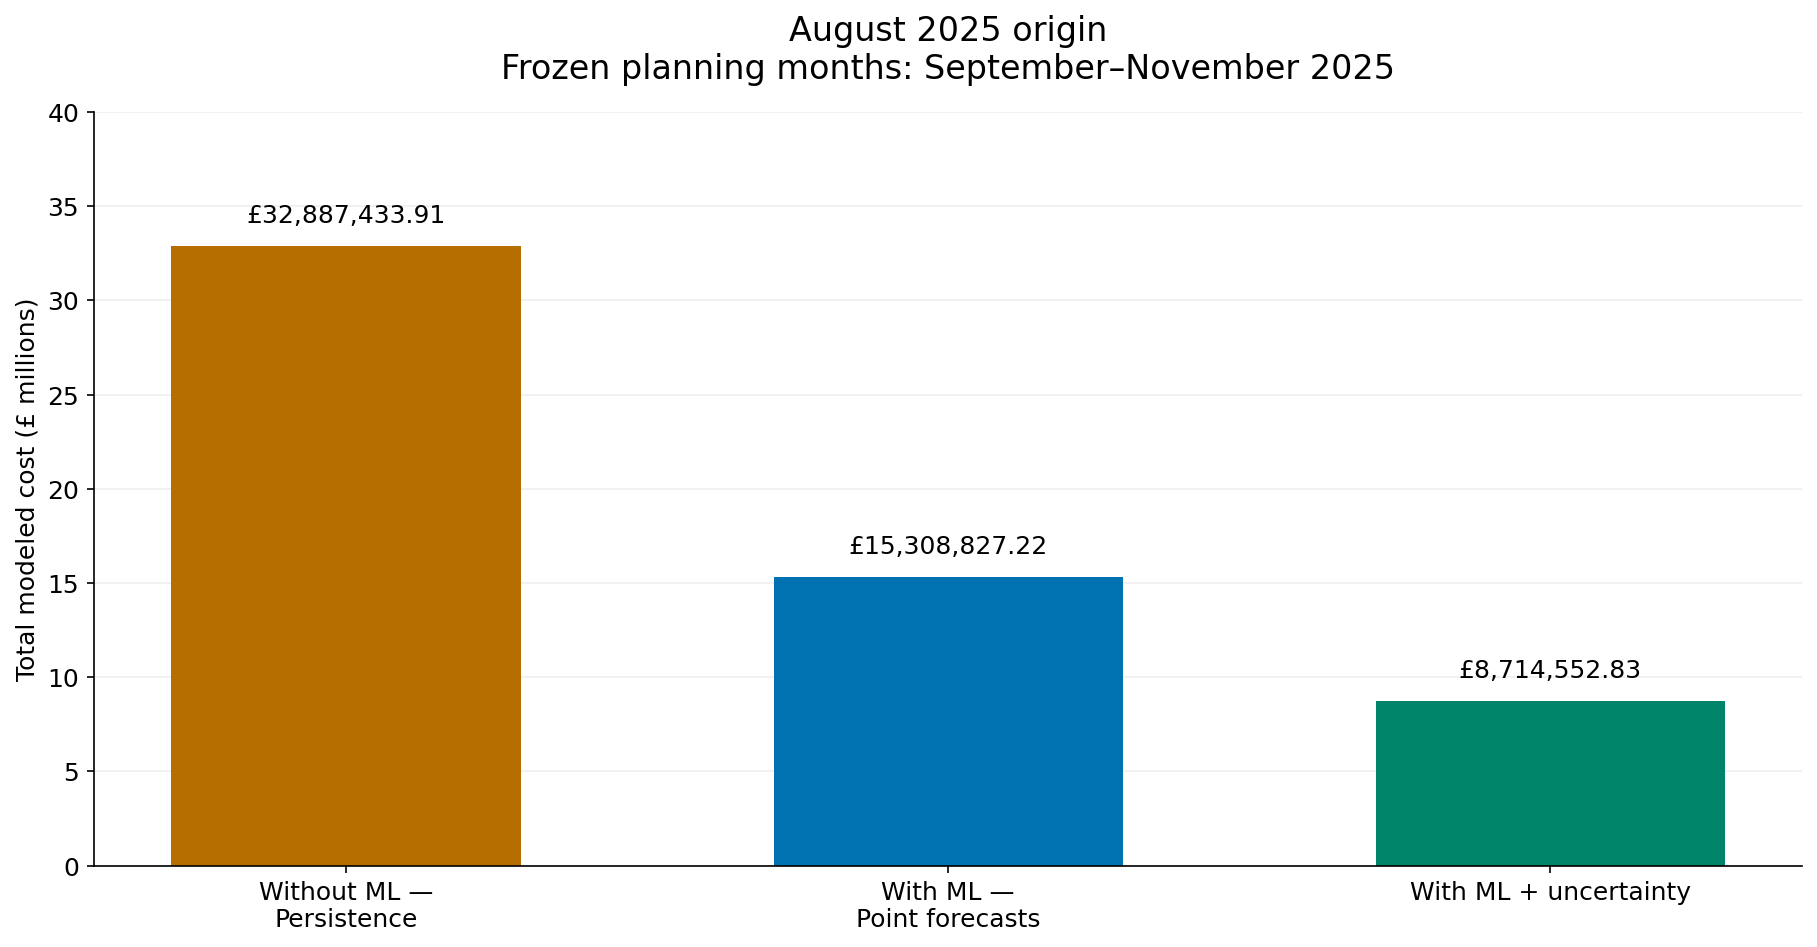

Three-month frozen plan; illustrative modeled costs, not NHS cash savings.

In [1]:
# Presentation only: load stored realized block costs; never fit or optimize.
from pathlib import Path as PresentationPath
import math as presentation_math
import pandas as presentation_pd
import matplotlib.pyplot as presentation_plt
from IPython.display import Markdown as PresentationMarkdown, Image as PresentationImage, display as presentation_display

presentation_output = PresentationPath.cwd() / "outputs/frozen_three_month_uncertainty_optimization"
presentation_blocks = presentation_pd.read_csv(
    presentation_output / "per_origin_policy_summary.csv", parse_dates=["forecast_origin"])
presentation_policies = ["frozen_persistence", "frozen_locked_ml", "frozen_ml_uncertainty"]
presentation_labels = ["Without ML \u2014 Persistence", "With ML \u2014 Point forecasts", "With ML + uncertainty"]
presentation_colors = ["#B76E00", "#0072B2", "#00856A"]
presentation_origins = presentation_pd.to_datetime(["2025-08-01", "2025-11-01", "2026-02-01"])
presentation_blocks = presentation_blocks[
    presentation_blocks.forecast_origin.isin(presentation_origins)
    & presentation_blocks.policy.isin(presentation_policies)].copy()
assert len(presentation_blocks) == 9
assert not presentation_blocks.duplicated(["forecast_origin", "policy"]).any()
assert presentation_blocks.total_modeled_cost.notna().all()
assert (presentation_blocks.total_modeled_cost >= 0).all()
# One common ceiling, derived from all nine stored costs, with room for labels.
presentation_ymax = 5 * presentation_math.ceil(
    presentation_blocks.total_modeled_cost.max() / 1_000_000 * 1.18 / 5)


def present_frozen_total_cost(origin, origin_label, planning_months, anchors, filename, carried=False):
    block = presentation_blocks[
        presentation_blocks.forecast_origin == presentation_pd.Timestamp(origin)
    ].set_index("policy").loc[presentation_policies]
    values = block.total_modeled_cost.to_numpy(dtype=float)
    # Anchors check penny rounding only; chart and table values come from the CSV.
    assert all(abs(value - anchor) <= 0.0051 for value, anchor in zip(values, anchors))
    assert all(abs(block.total_modeled_cost - block.operational_cost - block.shortage_cost) < 1e-7)
    presentation_display(PresentationMarkdown(
        f"## {origin_label} origin\n\n**Frozen planning months: {planning_months}.**"))
    cost_table = presentation_pd.DataFrame({
        "Policy": presentation_labels,
        "Total modeled cost (GBP)": [f"\u00a3{value:,.2f}" for value in values],
    })
    presentation_display(cost_table.style.hide(axis="index"))
    with presentation_plt.rc_context({"font.size": 12, "axes.spines.top": False,
                                      "axes.spines.right": False, "axes.grid": False}):
        fig, ax = presentation_plt.subplots(figsize=(12, 6.2), layout="constrained")
        bars = ax.bar(range(3), values / 1_000_000, color=presentation_colors, width=0.58)
        ax.set_xticks(range(3), ["Without ML \u2014\nPersistence", "With ML \u2014\nPoint forecasts",
                                "With ML + uncertainty"])
        ax.set_ylim(0, presentation_ymax)
        ax.set_yticks(range(0, int(presentation_ymax) + 1, 5))
        ax.set_ylabel("Total modeled cost (\u00a3 millions)")
        ax.set_title(f"{origin_label} origin\nFrozen planning months: {planning_months}", fontsize=16, pad=16)
        ax.set_axisbelow(True)
        ax.yaxis.grid(True, alpha=0.2)
        ax.bar_label(bars, labels=[f"\u00a3{value:,.2f}" for value in values], padding=9, fontsize=12)
        image_path = presentation_output / filename
        fig.savefig(image_path, dpi=150, bbox_inches="tight")
        presentation_display(PresentationImage(data=image_path.read_bytes()))
        presentation_plt.close(fig)
    presentation_display(PresentationMarkdown(
        "Three-month frozen plan; illustrative modeled costs, not NHS cash savings."))
    if carried:
        presentation_display(PresentationMarkdown(
            "Starting capacity is carried forward from each policy's previous block."))


present_frozen_total_cost(
    "2025-08-01", "August 2025", "September\u2013November 2025",
    [32_887_433.91, 15_308_827.22, 8_714_552.83],
    "presentation_total_cost_august_2025.png")

## November 2025 origin

**Frozen planning months: December 2025–February 2026.**

Policy,Total modeled cost (GBP)
Without ML — Persistence,"£14,530,766.34"
With ML — Point forecasts,"£8,289,374.25"
With ML + uncertainty,"£9,331,041.93"


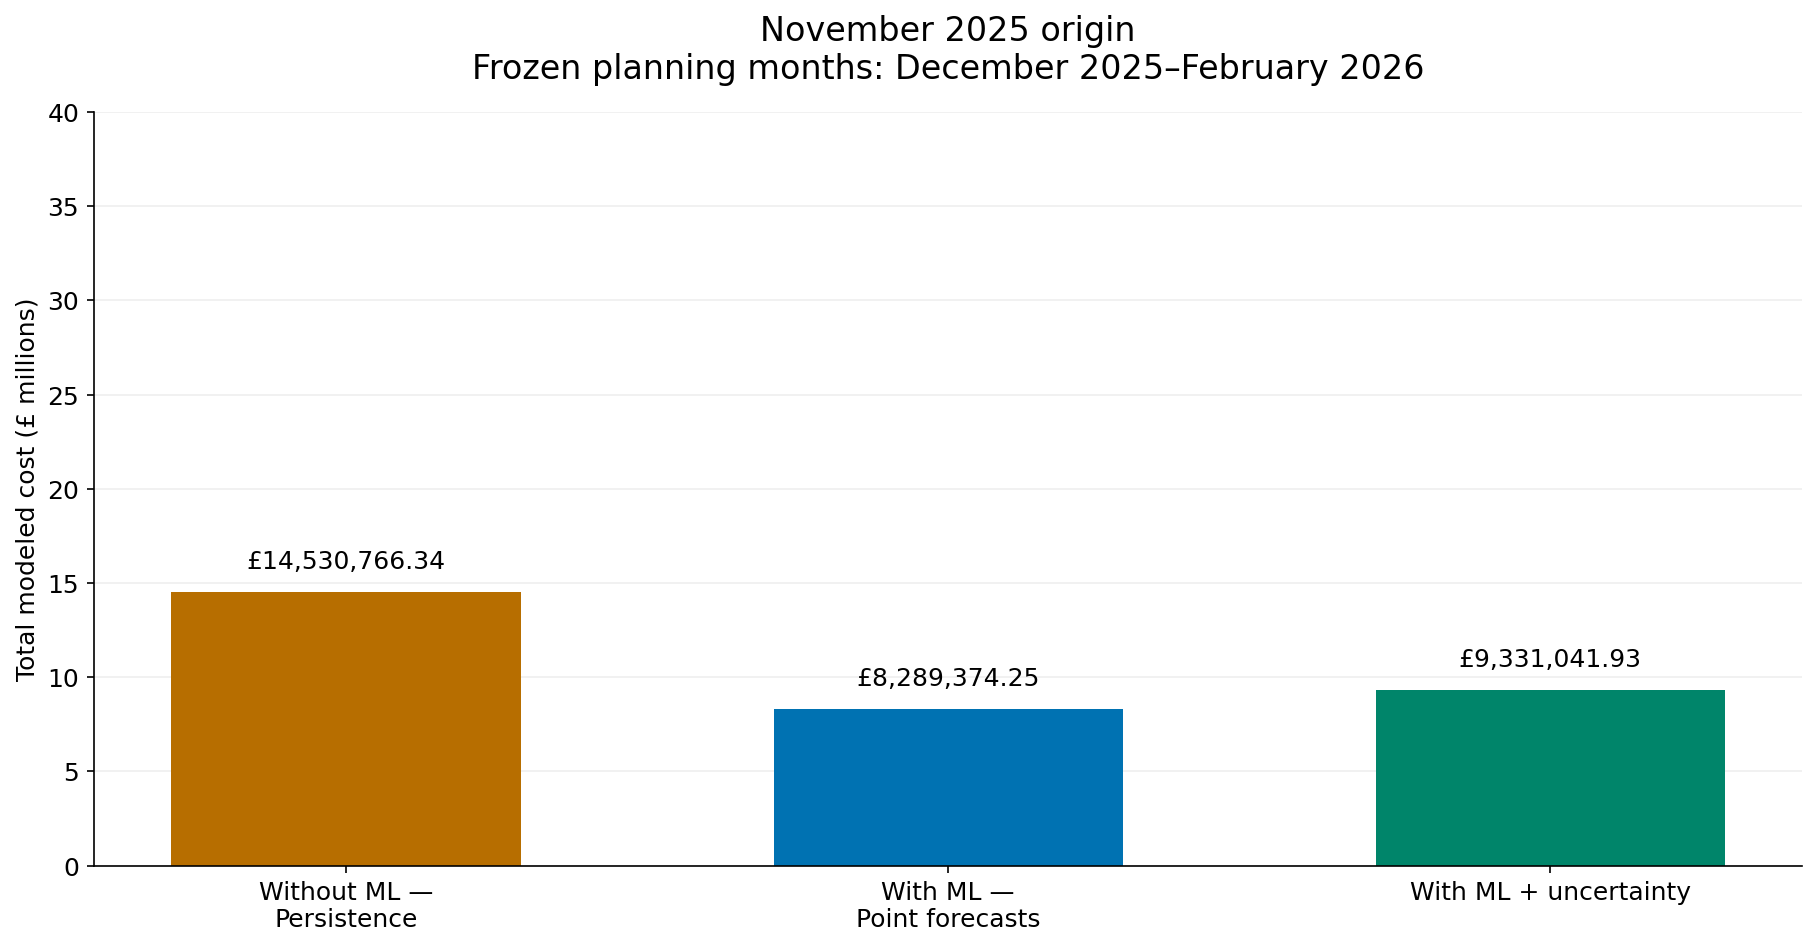

Three-month frozen plan; illustrative modeled costs, not NHS cash savings.

Starting capacity is carried forward from each policy's previous block.

In [2]:
present_frozen_total_cost(
    "2025-11-01", "November 2025", "December 2025\u2013February 2026",
    [14_530_766.34, 8_289_374.25, 9_331_041.93],
    "presentation_total_cost_november_2025.png", carried=True)

## February 2026 origin

**Frozen planning months: March–May 2026.**

Policy,Total modeled cost (GBP)
Without ML — Persistence,"£7,322,827.70"
With ML — Point forecasts,"£12,572,337.66"
With ML + uncertainty,"£7,343,439.62"


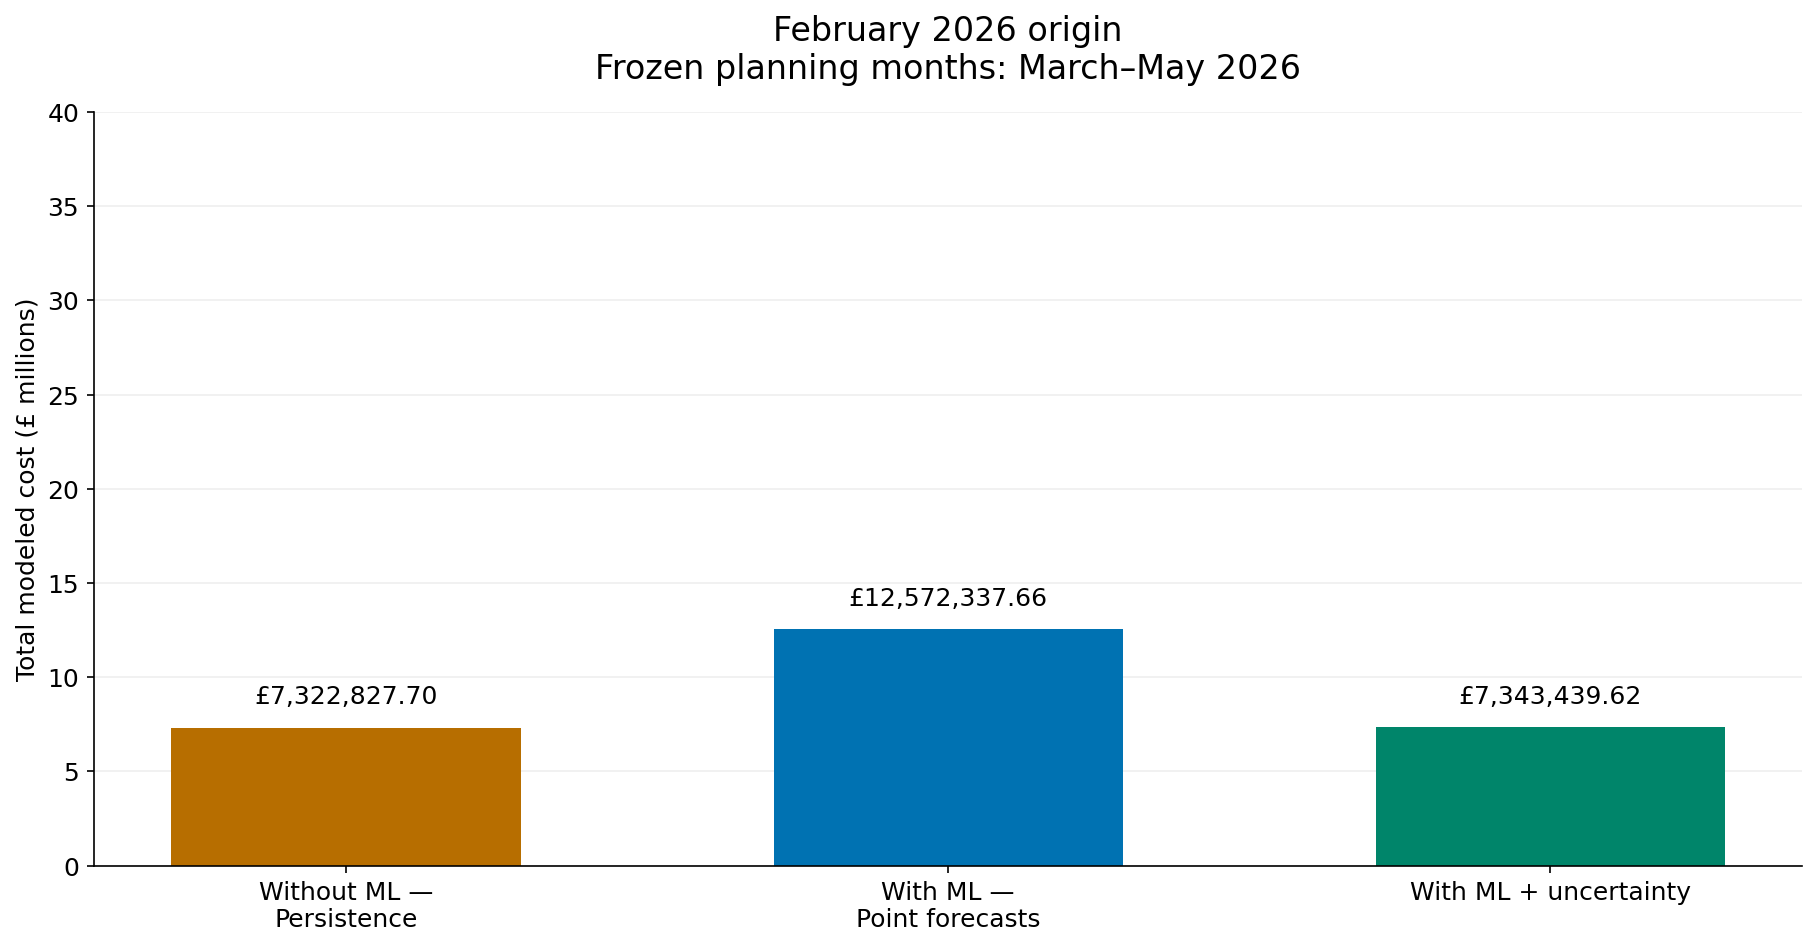

Three-month frozen plan; illustrative modeled costs, not NHS cash savings.

Starting capacity is carried forward from each policy's previous block.

In [3]:
present_frozen_total_cost(
    "2026-02-01", "February 2026", "March\u2013May 2026",
    [7_322_827.70, 12_572_337.66, 7_343_439.62],
    "presentation_total_cost_february_2026.png", carried=True)